#**AT - ESTATÍSTICA APLICADA E ANÁLISE EXPLORATÓRIA DE DADOS**

## Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import bootstrap

## Funções reutilizáveis

In [ ]:
ARQUIVOS_BASE = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
}

COLUNAS_DATA_PEDIDO = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

def carregar_bases(arquivos = ARQUIVOS_BASE):
    """Lê os CSV's do marketplace e devolve um dicionário com o nome e o dataframe"""

    return {nome: pd.read_csv(caminho) for nome, caminho in arquivos.items()}

def carregar_reviews_por_pedido(caminho = "olist_order_reviews_dataset.csv"):
    """Devolve uma linha por order_id com a nota, para o merge não multiplicar linhas"""

    df_reviews = pd.read_csv(caminho)
    return df_reviews.drop_duplicates(subset = "order_id", keep = "first")[["order_id", "review_score"]]

def converter_colunas_para_datetime(df, colunas):
    """Converte as colunas informadas para datetime64 e devolve o próprio dataframe"""

    for coluna in colunas:
        df[coluna] = pd.to_datetime(df[coluna], errors = "coerce")

    return df

def consolidar_bases(bases):
    """Une as fontes em um único dataframe na granularidade de item de pedido"""

    return (
        bases["order_items"]
        .merge(bases["orders"], on = "order_id", how = "left")
        .merge(bases["products"], on = "product_id", how = "left")
        .merge(bases["customers"], on = "customer_id", how = "left")
        .merge(bases["sellers"], on = "seller_id", how = "left")
    )

def limpar_dataframe(df, colunas_obrigatorias = None, chave_duplicatas = None):
    """Remove nulos das colunas obrigatórias e duplicatas da chave, mostrando o impacto de cada etapa"""

    df_limpo = df.copy()

    if colunas_obrigatorias:
        antes = len(df_limpo)
        df_limpo = df_limpo.dropna(subset = colunas_obrigatorias)
        print("Linhas removidas por nulo em", colunas_obrigatorias, ":", antes - len(df_limpo))

    if chave_duplicatas:
        antes = len(df_limpo)
        df_limpo = df_limpo.drop_duplicates(subset = chave_duplicatas, keep = "first")
        print("Linhas removidas por duplicata em", chave_duplicatas, ":", antes - len(df_limpo))

    print("Shape:", df.shape, "->", df_limpo.shape)
    return df_limpo

def resumir_outliers_iqr(serie):
    """Aplica a regra de 1,5 x IQR e devolve limites, contagem e percentual de outliers"""

    valores = serie.dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    intervalo_iqr = q3 - q1
    limite_inferior = q1 - 1.5 * intervalo_iqr
    limite_superior = q3 + 1.5 * intervalo_iqr

    abaixo = int((valores < limite_inferior).sum())
    acima = int((valores > limite_superior).sum())

    return pd.Series({
        "variavel": serie.name,
        "n_validos": len(valores),
        "q1": round(q1, 2),
        "q3": round(q3, 2),
        "iqr": round(intervalo_iqr, 2),
        "limite_inferior": round(limite_inferior, 2),
        "limite_superior": round(limite_superior, 2),
        "outliers_abaixo": abaixo,
        "outliers_acima": acima,
        "outliers_total": abaixo + acima,
        "outliers_pct": round((abaixo + acima) / len(valores) * 100, 2),
    })

def plotar_hist_box(serie, nome_variavel, bins = 60):
    """Monta o histograma com o boxplot em cima, dividindo o mesmo eixo x"""

    valores = serie.dropna()
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize = (8, 6), sharex = True, gridspec_kw = {"height_ratios": [1, 4]})

    ax_box.boxplot(valores, vert = False, widths = 0.6)
    ax_box.set_yticks([])
    ax_hist.hist(valores, bins = bins, edgecolor = "black")
    ax_hist.set_xlabel(nome_variavel)
    ax_box.set_title(f"{nome_variavel}: boxplot + histograma")

    plt.tight_layout()
    plt.show()

def ajustar_reta_minimos_quadrados(x, y):
    """Calcula o coeficiente linear e o angular da reta de regressão simples"""

    x = np.asarray(x, dtype = float)
    y = np.asarray(y, dtype = float)

    coeficiente_angular = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    coeficiente_linear = y.mean() - coeficiente_angular * x.mean()

    return coeficiente_linear, coeficiente_angular

def proporcao_avaliacoes_negativas(df, reviews, por_pedido = False):
    """Proporção de registros com nota 1 ou 2, desconsiderando os que não têm avaliação"""

    base = df[["order_id"]].drop_duplicates() if por_pedido else df[["order_id"]]
    base = base.merge(reviews, on = "order_id", how = "left").dropna(subset = ["review_score"])
    return (base["review_score"] <= 2).mean(), len(base)

def avaliar_modelo(df, preditoras, alvo = "freight_value"):
    """Ajusta a regressão com as preditoras informadas e devolve R² e RMSE no conjunto de teste"""

    X_treino, X_teste, y_treino, y_teste = train_test_split(df[preditoras], df[alvo], test_size = 0.2, random_state = 42)

    modelo = LinearRegression().fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)

    return r2_score(y_teste, previsto), np.sqrt(mean_squared_error(y_teste, previsto))

def intervalo_confianca_media(notas, n_reamostragens = 9999, semente = 42):
    """Intervalo de confiança de 95% da média, calculado por bootstrap percentil"""

    resultado = bootstrap(
        (notas,),
        np.mean,
        confidence_level = 0.95,
        n_resamples = n_reamostragens,
        method = "percentile",
        batch = 100,
        random_state = semente,
    )

    return resultado.confidence_interval.low, resultado.confidence_interval.high

#AT - Respostas

## **EXERCÍCIO 1**

### 1.1 Carregue os arquivos olist_orders_dataset.csv, olist_order_items_dataset.csv, olist_products_dataset.csv, olist_customers_dataset.csv e olist_sellers_dataset.csv com pandas.read_csv.

In [ ]:
bases = carregar_bases()

df_orders = bases["orders"]
df_order_items = bases["order_items"]
df_products = bases["products"]
df_customers = bases["customers"]
df_sellers = bases["sellers"]

print("Bases carregadas:", list(bases))

Bases carregadas: ['orders', 'order_items', 'products', 'customers', 'sellers']


Carreguei os arquivos utilizando a função carregar_bases, que internamente usa o *pandas.read_csv*.

### 1.2 Para cada um dos cinco DataFrames, inspecione shape, dtypes e info(), registrando o número de linhas, colunas e o tipo inferido para cada uma.

In [ ]:
lista_dataframes = [
    ("df_orders", df_orders),
    ("df_order_items", df_order_items),
    ("df_products", df_products),
    ("df_customers", df_customers),
    ("df_sellers", df_sellers),
]

for nome, df in lista_dataframes:
    print("=================")
    print(f"\nNome: {nome}")
    print("Shape:", df.shape)

    print("\nDtypes:")
    print(df.dtypes)

    print("\nInfo:")
    df.info()

    print("\nValores ausentes por coluna:")
    nulos = df.isna().sum()
    print(nulos[nulos > 0] if (nulos > 0).any() else "Nenhuma coluna com valor ausente")
    print()


Nome: df_orders
Shape: (99441, 8)

Dtypes:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date 

Para não repetir o mesmo bloco cinco vezes, criei uma lista de tuplas com os cinco dataframes, e percorri a lista imprimindo o *shape*, o *dtype* e o *info* de cada um, mostrando também o número de linhas vazias.

### 1.3 Escreva, em uma célula de markdown, três observações sobre os dados com base nessa inspeção (por exemplo, colunas de data lidas como texto, ou colunas com muitos valores ausentes).

1. O dataset *df_sellers* possui apenas 3095 linhas, muito menos do que a quantidade de produtos, clientes e pedidos, o que é coerente considerando que um vendedor pode realizar múltiplas vendas de vários produtos para diversos clientes.

2. Todas as colunas de datas foram lidas como *object*, ou seja, texto, tornando necessário realizar a conversão para *datetime* antes de realizar qualquer operação com elas. As colunas em questão são:

* *order_purchase_timestamp*
* *order_approved_at*
* *df_orders.order_delivered_carrier_date*
* *df_orders.order_delivered_customer_date*
* *df_orders.order_estimated_delivery_date*
* *df_order_items.shipping_limit_date*

3. No dataset *df_products*, as colunas *product_category_name*, *product_name_lenght*, *product_description_lenght* e *product_photos_qty* possuem todas 610 linhas com valores nulos, indicando que provavelmente se tratam dos mesmos produtos que não tiveram o cadastro concluído. Além disso, as colunas referentes a dimensão, *product_weight_g, product_length_cm, product_height_cm* e *product_width_cm*, estão com duas linhas nulas, indicando que dois produtos foram preenchidos com exceção dos valores das dimensões.

## **EXERCÍCIO 2**

### 2.1 Converta order_purchase_timestamp, order_delivered_customer_date e order_estimated_delivery_date (do DataFrame de pedidos) para datetime64.

In [ ]:
converter_colunas_para_datetime(df_orders, COLUNAS_DATA_PEDIDO)

print(df_orders.dtypes)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


Realizei a conversão para datetime64 das colunas order_purchase_timestamp, order_delivered_customer_date e order_estimated_delivery_date, usando a função converter_colunas_para_datetime, que internamente usa *pd.to_datetime*.

### 2.2 Combine os cinco DataFrames do Exercício 1 em um único DataFrame consolidado, unindo pedidos com itens de pedido, produtos, clientes e vendedores pelas chaves apropriadas (order_id, product_id, customer_id, seller_id).

In [ ]:
pedidos_sem_item = (~df_orders["order_id"].isin(df_order_items["order_id"])).sum()
print("Pedidos sem nenhum item em olist_order_items:", pedidos_sem_item)

df_consolidado = consolidar_bases(bases)

print("Shape df_consolidado:", df_consolidado.shape)

Pedidos sem nenhum item em olist_order_items: 775
Shape df_consolidado: (112650, 29)


Montei o dataframe consolidado iniciando pelo *df_order_items*, e usando *how = "left"* nos quatro merges, já que a granularidade final desejada é a do item do pedido, que é a informação central que é enriquecida com os merges que trazem as informações sobre o produto, o cliente e o vendedor. Com o merge feito dessa forma, 775 pedidos que não têm nenhum item ficam fora do dataframe, mas pedidos sem item provavelmente são pedidos cancelados ou erro de cadastro, não sendo relevantes para as análises seguintes.

### 2.3 Confirme o número final de linhas e colunas do DataFrame consolidado, e imprima os dtypes das colunas de data já convertidas.

In [ ]:
print("Linhas e colunas do dataframe consolidado:", df_consolidado.shape)
print("\nColunas de datas convertidas:")
print(df_consolidado[COLUNAS_DATA_PEDIDO].dtypes)

Linhas e colunas do dataframe consolidado: (112650, 29)

Colunas de datas convertidas:
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


O dataframe consolidado terminou com as mesmas 112650 linhas do *df_order_items*, confirmando que as linhas não foram duplicadas. Além disso, as três colunas de data permanecem como *datetime64*.

## **EXERCÍCIO 3**

### 3.1 Escolha uma categoria de produto (product_category_name) com pelo menos 200 pedidos no DataFrame consolidado, e documente qual categoria escolheu e por quê.

In [ ]:
itens_por_categoria = df_consolidado["product_category_name"].value_counts()
pedidos_por_categoria = df_consolidado.groupby("product_category_name")["order_id"].nunique()

resumo_categorias = pd.DataFrame({
    "itens": itens_por_categoria,
    "pedidos_distintos": pedidos_por_categoria,
}).sort_values("itens", ascending = False)

print(resumo_categorias.head(10))

                        itens  pedidos_distintos
product_category_name                           
cama_mesa_banho         11115               9417
beleza_saude             9670               8836
esporte_lazer            8641               7720
moveis_decoracao         8334               6449
informatica_acessorios   7827               6689
utilidades_domesticas    6964               5884
relogios_presentes       5991               5624
telefonia                4545               4199
ferramentas_jardim       4347               3518
automotivo               4235               3897


Escolhi a categoria *beleza_saude*, por ser a segunda categoria mais frequente no dataset, com 9670 linhas no dataframe consolidado, distribuídas em 8836 pedidos distintos. Por possuir um grande volume de dados, é uma boa escolha de categoria para fazer análises seguindo ela.

### 3.2 Selecione as colunas relevantes para o relatório executivo (order_id, product_category_name, price, freight_value, seller_state) usando loc, e filtre as linhas para pedidos com status delivered da categoria escolhida, usando tanto notação booleana composta quanto query().

In [ ]:
colunas_relatorio = ["order_id", "product_category_name", "price", "freight_value", "seller_state"]

recorte_booleano = df_consolidado.loc[
    (df_consolidado["order_status"] == "delivered") & (df_consolidado["product_category_name"] == "beleza_saude"),
    colunas_relatorio
]

recorte_query = df_consolidado.query(
    "order_status == 'delivered' and product_category_name == 'beleza_saude'"
)[colunas_relatorio]

print("Shape - booleana composta:", recorte_booleano.shape)
print("Shape - query:", recorte_query.shape)
print("Recortes são iguais:", recorte_booleano.reset_index(drop = True).equals(recorte_query.reset_index(drop = True)))

Shape - booleana composta: (9465, 5)
Shape - query: (9465, 5)
Recortes são iguais: True


Os dois recortes possuem as mesmas condições, e por isso têm o mesmo resultado, mesmo usando métodos diferentes.

### 3.3 Extraia, com iloc, uma amostra das 20 primeiras linhas do recorte filtrado para uma verificação rápida.

In [ ]:
amostra_20 = recorte_booleano.iloc[:20]
amostra_20

,order_id,product_category_name,price,freight_value,seller_state
8,0005a1a1728c9d785b8e2b08b904576c,beleza_saude,145.95,11.65,SP
10,00061f2a7bc09da83e415a52dc8a4af1,beleza_saude,59.99,8.88,SP
48,001d8f0e34a38c37f7dba2a37d4eba8b,beleza_saude,18.99,7.78,SP
49,001d8f0e34a38c37f7dba2a37d4eba8b,beleza_saude,18.99,7.78,SP
53,001e7cf2ad6bef3ade12ebc56ceaf0f3,beleza_saude,35.90,15.20,MG
70,0029c5db35ef291ce99d1262012e7daa,beleza_saude,492.75,21.62,SP
94,00345f338696283410b7977d2e3efc89,beleza_saude,48.90,18.44,RJ
109,003d9fc84ad902adf2265248b5ffe1a4,beleza_saude,66.99,27.75,MA
120,0045e3085f083f0f38d24bb3f22e6593,beleza_saude,116.90,13.84,SP
127,004b62108b876867938746ad3154167f,beleza_saude,110.32,8.03,SP


Foram extraídas na amostra as 20 primeiras linhas do recorte com o *iloc*.

## **EXERCÍCIO 4**

### 4.1 Trate os valores ausentes em product_category_name com uma estratégia justificada, remova duplicatas remanescentes por order_id e product_id, e calcule o preço médio e o frete médio por categoria sobre o DataFrame consolidado e limpo.

In [ ]:
nulos_categoria = df_consolidado["product_category_name"].isna().sum()
pct_nulos_categoria = df_consolidado["product_category_name"].isna().mean() * 100
print("Linhas com product_category_name nulo:", nulos_categoria, f"({pct_nulos_categoria:.2f}%)\n")

df_consolidado_limpo = limpar_dataframe(
    df_consolidado,
    colunas_obrigatorias = ["product_category_name"],
    chave_duplicatas = ["order_id", "product_id"],
)

preco_frete_por_categoria = (
    df_consolidado_limpo
    .groupby("product_category_name")[["price", "freight_value"]]
    .mean()
    .rename(columns = {"price": "preco_medio", "freight_value": "frete_medio"})
    .sort_values("preco_medio", ascending = False)
)

print("\nCategorias na tabela agregada:", len(preco_frete_por_categoria))
print(preco_frete_por_categoria)

Linhas com product_category_name nulo: 1603 (1.42%)

Linhas removidas por nulo em ['product_category_name'] : 1603
Linhas removidas por duplicata em ['order_id', 'product_id'] : 10082
Shape: (112650, 29) -> (100965, 29)

Categorias na tabela agregada: 73
                             preco_medio  frete_medio
product_category_name                                
pcs                          1141.459558    49.239227
portateis_casa_forno_e_cafe   624.285658    36.156053
eletrodomesticos_2            483.264786    45.011496
agro_industria_e_comercio     351.167650    28.114973
instrumentos_musicais         293.112673    27.528522
...                                  ...          ...
bebidas                        57.019371    14.740066
cds_dvds_musicais              53.333333    16.064167
fraldas_higiene                46.466296    15.487407
flores                         33.204828    14.720690
casa_conforto_2                28.452917    13.610833

[73 rows x 2 columns]


Como *product_category_name* é um identificador de categoria, e não uma métrica numérica, não é possível ou faz sentido preencher os nulos com a média ou mediana. Como só existem 1603 linhas com a categoria nula, o que representa somente 1,42% da base total, e o objetivo é justamente comparar a métrica entre diferentes categorias, optei por remover essas linhas, ao invés de criar uma categoria artificial como "não informado", que iria apenas poluir a tabela com uma linha sem significado de negócio.

Sobre as duplicatas, realizei a remoção pela chave *order_id* e *product_id*, o que tirou 10082 linhas e pode ter removido itens em que o cliente selecionou mais de uma unidade do mesmo produto, já que o *order_item_id* pode ser diferente entre os itens. Porém, para o cálculo de preço e frete médio por categoria, esse efeito é aceitável, porque cada combinação de pedido e produto passa a pesar apenas uma vez nos cálculos realizados.

### 4.2 A partir dessa tabela agregada por categoria, formule manualmente a equação da reta de regressão simples entre o preço médio e o frete médio das categorias (coeficiente linear e angular), e indique o que o coeficiente angular sugere sobre a relação entre as duas métricas.

In [ ]:
coeficiente_linear, coeficiente_angular = ajustar_reta_minimos_quadrados(
    preco_frete_por_categoria["preco_medio"],
    preco_frete_por_categoria["frete_medio"],
)

print(f"Equação da reta: frete_medio = {coeficiente_linear:.4f} + {coeficiente_angular:.4f} * preco_medio")
print("Coeficiente angular:", round(coeficiente_angular, 4))
print("Coeficiente linear:", round(coeficiente_linear, 4))

Equação da reta: frete_medio = 16.4970 + 0.0351 * preco_medio
Coeficiente angular: 0.0351
Coeficiente linear: 16.497


Ao nível da categoria, a equação ajustada é: *frete_medio ≈ 16,4970 + 0,0351 × preco_medio*.

O coeficiente angular positivo, ≈0,0351, indica que as categorias com preços médios mais altos tendem a ter um frete mais alto, porém com um baixo efeito, um aumento de R\$ 100,00 no preço médio da categoria aumenta apenas R\$ 3,51 no frete médio esperado.

Já o coeficiente linear, ≈16,50, representa um custo de frete base relativamente alto até mesmo para as categorias de preços baixos, o que sugere que o valor do frete possui um componente fixo não relacionado ao valor do produto, provavelmente ligado ao peso e dimensão do produto.

Essas informações são um indício inicial de que o preço por si só é um preditor fraco do frete, algo que a diretoria pode querer investigar com outras variáveis, como peso e dimensão do produto, antes de decidir sobre a precificação do frete no próximo trimestre.

## **EXERCÍCIO 5**

### 5.1 Crie uma coluna booleana indicando se cada pedido entregue chegou depois da data estimada (order_delivered_customer_date posterior a order_estimated_delivery_date).

In [ ]:
df_payments = pd.read_csv("olist_order_payments_dataset.csv")
parcelas_por_pedido = df_payments.groupby("order_id")["payment_installments"].max().rename("parcelas_max")

pedidos_entregues = (
    df_consolidado[
        (df_consolidado["order_status"] == "delivered") &
        (df_consolidado["order_delivered_customer_date"].notna())
    ]
    .drop_duplicates(subset = "order_id")
    [["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]]
    .merge(parcelas_por_pedido, on = "order_id", how = "left")
)

pedidos_entregues["atraso"] = pedidos_entregues["order_delivered_customer_date"] > pedidos_entregues["order_estimated_delivery_date"]

print("Pedidos entregues:", len(pedidos_entregues))
print(pedidos_entregues["atraso"].value_counts())

Pedidos entregues: 96470
atraso
False    88644
True      7826
Name: count, dtype: int64


Optei por aplicar a nova coluna sobre uma tabela deduplicada por *order_id*, ao invés de usar diretamente *df_consolidado*, já que *order_delivered_customer_date* e *order_estimated_delivery_date* são informações do pedido e não do item, calcular a probabilidade sem realizar a deduplicação antes faria com que um pedido com vários itens tivesse mais peso do que um pedido com um único item, distorcendo a frequência relativa.

Além disso, filtrei por *order_status == "delivered"* e data de entrega não nula antes de realizar a comparação de datas, para evitar que linhas sem datas aparecessem como "não atrasado".

### 5.2 Calcule a probabilidade de um pedido entregue atrasar, usando frequência relativa sobre a base consolidada.

In [ ]:
p_atraso = pedidos_entregues["atraso"].mean()
print("P(atraso | pedido entregue):", round(p_atraso, 4))

P(atraso | pedido entregue): 0.0811


Realizei o cálculo da probabilidade pela frequência relativa, dividindo os casos de atraso pelo total de pedidos entregues.

### 5.3 Calcule a probabilidade de um pedido atrasar E ter sido pago em mais de uma parcela, usando a regra da multiplicação.

In [ ]:
pedidos_entregues["parcelado"] = pedidos_entregues["parcelas_max"] > 1

p_parcelado = pedidos_entregues["parcelado"].mean()
p_atraso_dado_parcelado = pedidos_entregues.loc[pedidos_entregues["parcelado"], "atraso"].mean()

p_atraso_e_parcelado = p_parcelado * p_atraso_dado_parcelado

print("P(parcelado):", round(p_parcelado, 4))
print("P(atraso | parcelado):", round(p_atraso_dado_parcelado, 4))
print("P(atraso E parcelado):", round(p_atraso_e_parcelado, 4))

P(parcelado): 0.5147
P(atraso | parcelado): 0.0828
P(atraso E parcelado): 0.0426


Realizei o cálculo utilizando a regra da multiplicação, em que P(A e B) = P(B) × P(A|B), sendo A o atraso, e B o pagamento parcelado.

### 5.4 Calcule a probabilidade de um pedido atrasar OU ter sido pago em mais de uma parcela, usando a regra da adição a partir das probabilidades marginais e da interseção.

In [ ]:
p_atraso_ou_parcelado = p_atraso + p_parcelado - p_atraso_e_parcelado

print("P(atraso OU parcelado):", round(p_atraso_ou_parcelado, 4))

P(atraso OU parcelado): 0.5532


Calculei a probabilidade usando a regra da adição, em que P(A ou B) = P(A) + P(B) − P(A e B), sendo A o atraso, e B o pagamento parcelado.

## **EXERCÍCIO 6**

### 6.1 Classifique freight_value e review_score quanto ao tipo (contínua ou discreta), justificando cada classificação com base no comportamento real dos dados.

In [ ]:
reviews_por_pedido = carregar_reviews_por_pedido()

print("Freight_value (valores únicos):", df_consolidado["freight_value"].nunique(), "de", len(df_consolidado))
print("Freight_value (menores valores):", np.sort(df_consolidado["freight_value"].dropna().unique())[:8])
print("Review_score (valores únicos):", sorted(reviews_por_pedido["review_score"].unique()))

Freight_value (valores únicos): 6999 de 112650
Freight_value (menores valores): [0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07]
Review_score (valores únicos): [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


A coluna *freight_value* é contínua, já que ela mede um valor monetário que pode assumir qualquer valor decimal dentro de um intervalo, trazendo um total de 6999 valores distintos entre 112650 itens, variando de centavo em centavo. Já *review_score* é discreta, sendo que ela assume só 5 valores possíveis, sendo eles 1, 2, 3, 4 ou 5, sempre inteiros, sendo uma nota de avaliação, não uma medida contínua.

### 6.2 Calcule a probabilidade de um pedido ter freight_value acima de R$ 30, usando a CDF empírica da variável.

In [ ]:
freight_ordenado = np.sort(df_consolidado["freight_value"].dropna())
n_itens = len(freight_ordenado)

posicao_corte_30 = np.searchsorted(freight_ordenado, 30, side = "right")
cdf_em_30 = posicao_corte_30 / n_itens
p_acima_30 = 1 - cdf_em_30

print("Itens com freight_value <= 30:", posicao_corte_30, "de", n_itens)
print("CDF empírica em R$30 -> P(freight_value <= 30):", round(cdf_em_30, 4))
print("P(freight_value > 30):", round(p_acima_30, 4))

Itens com freight_value <= 30: 99619 de 112650
CDF empírica em R$30 -> P(freight_value <= 30): 0.8843
P(freight_value > 30): 0.1157


Para calcular a CDF empírica, que é a proporção de ocorrências que são menores ou iguais a um valor, ordenei a coluna e usei *np.searchsorted* para contar quantas observações são menores ou iguais a 30.

### 6.3 Considerando a equação da reta formulada no Exercício 4, calcule o valor de frete previsto por essa equação para uma categoria com preço médio 20% acima da média geral, e compare com o valor de frete médio realmente observado para categorias nessa faixa de preço.

In [ ]:
preco_medio_geral = preco_frete_por_categoria["preco_medio"].mean()
preco_alvo = preco_medio_geral * 1.20

frete_previsto = coeficiente_linear + coeficiente_angular * preco_alvo

faixa_inferior = preco_alvo * 0.85
faixa_superior = preco_alvo * 1.15
categorias_na_faixa = preco_frete_por_categoria[
    (preco_frete_por_categoria["preco_medio"] >= faixa_inferior) &
    (preco_frete_por_categoria["preco_medio"] <= faixa_superior)
].sort_values("frete_medio")

frete_observado_na_faixa = categorias_na_faixa["frete_medio"].mean()

print("Preço médio geral:", round(preco_medio_geral, 2))
print("Preço alvo (+20%):", round(preco_alvo, 2))
print("Frete previsto pela equação:", round(frete_previsto, 2))
print("Faixa de comparação:", round(faixa_inferior, 2), "a", round(faixa_superior, 2))
print("Categorias na faixa de comparação:", len(categorias_na_faixa))
print("Frete médio observado nessas categorias:", round(frete_observado_na_faixa, 2))
print("Diferença entre observado e previsto:", round(frete_observado_na_faixa - frete_previsto, 2))
print()
print(categorias_na_faixa.round(2))

Preço médio geral: 149.7
Preço alvo (+20%): 179.64
Frete previsto pela equação: 22.8
Faixa de comparação: 152.69 a 206.58
Categorias na faixa de comparação: 11
Frete médio observado nessas categorias: 26.51
Diferença entre observado e previsto: 3.71

                                                preco_medio  frete_medio
product_category_name                                                   
pc_gamer                                             165.87        15.48
relogios_presentes                                   204.78        16.81
telefonia_fixa                                       165.13        17.13
musica                                               158.80        18.17
cool_stuff                                           169.94        22.18
construcao_ferramentas_construcao                    168.45        22.41
climatizacao                                         181.55        22.53
industria_comercio_e_negocios                        156.24        29.34
moveis_escritorio  

Para uma categoria hipotética com o preço médio de R\$ 179,64, ou seja, 20% acima da média geral de R\$ 149,70, a equação formulada no exercício 4 prevê um frete médio de R\$ 22,80.

Nas 11 categorias reais com o preço médio nessa faixa, entre R\$ 152,69 e R\$ 206,58, o frete médio observado foi R\$ 26,51, sendo R\$ 3,71 acima do previsto, e com uma variação grande entre elas, de R\$ 15,48 em *pc_gamer* a R\$ 43,57 em *moveis_quarto*.

Essa dispersão reforça o que foi sugerido no exercício 4, o preço médio sozinho explica só parte do valor do frete de uma categoria. Por exemplo, as três categorias de móveis que aparecem na faixa puxam o frete para cima bem além do que o preço havia previsto, provavelmente por conta da dimensão e peso do produto.

## **EXERCÍCIO 7**

### 7.1 Construa um histograma com boxplot de freight_value, identificando outliers.

variavel           freight_value
n_validos                 112650
q1                         13.08
q3                         21.15
iqr                         8.07
limite_inferior             0.98
limite_superior            33.25
outliers_abaixo              521
outliers_acima             11613
outliers_total             12134
outliers_pct               10.77
dtype: object

Itens com freight_value igual a zero: 383


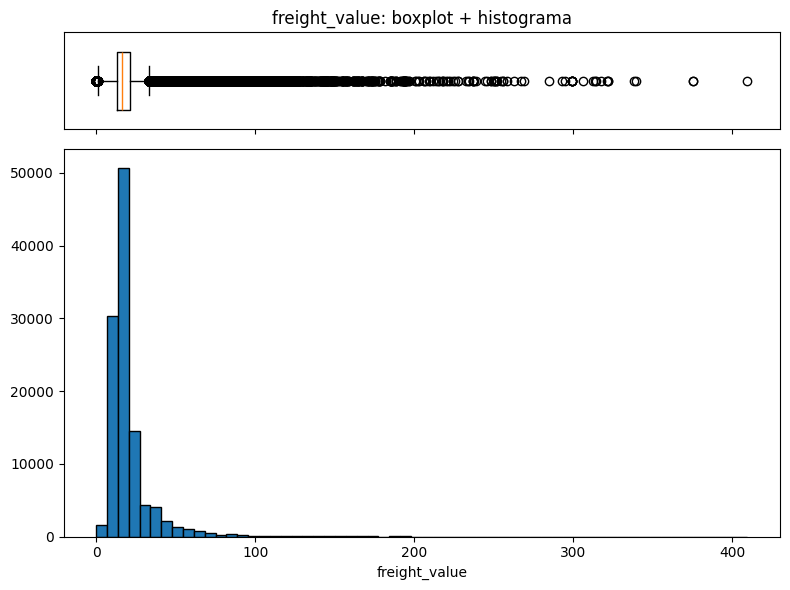

In [ ]:
resumo_outliers_frete = resumir_outliers_iqr(df_consolidado["freight_value"])
print(resumo_outliers_frete)
print("\nItens com freight_value igual a zero:", int((df_consolidado["freight_value"] == 0).sum()))

plotar_hist_box(df_consolidado["freight_value"], "freight_value")

Calculei os outliers pela regra de 1,5 × IQR, utilizando a função *resumir_outliers_iqr*, para melhor entendimento do boxplot.

### 7.2 Construa um histograma com boxplot de product_weight_g, identificando outliers.

variavel           product_weight_g
n_validos                    112632
q1                            300.0
q3                           1800.0
iqr                          1500.0
limite_inferior             -1950.0
limite_superior              4050.0
outliers_abaixo                   0
outliers_acima                15807
outliers_total                15807
outliers_pct                  14.03
dtype: object

Item mais pesado da base:
product_category_name    cama_mesa_banho
product_weight_g                 40425.0
freight_value                      16.32
price                               80.0
Name: 32763, dtype: object


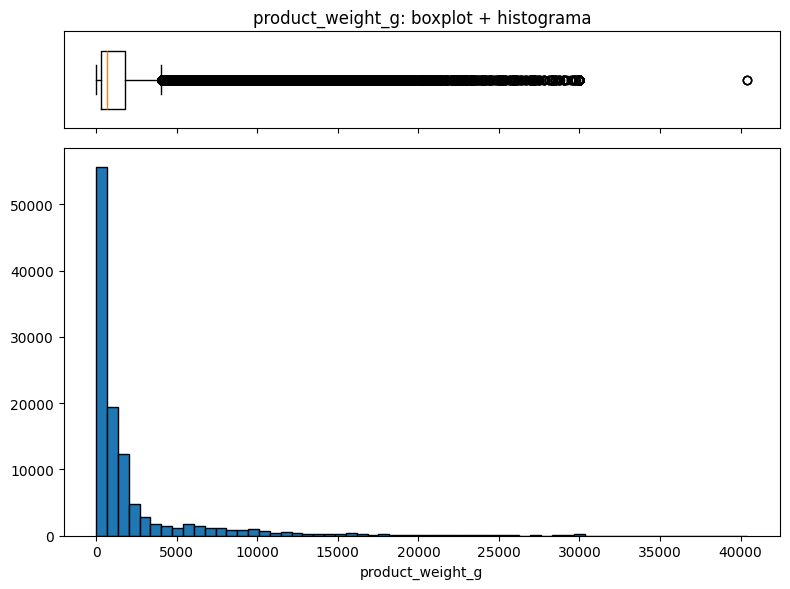

In [ ]:
resumo_outliers_peso = resumir_outliers_iqr(df_consolidado["product_weight_g"])
print(resumo_outliers_peso)

item_mais_pesado = df_consolidado.loc[df_consolidado["product_weight_g"].idxmax()]
print("\nItem mais pesado da base:")
print(item_mais_pesado[["product_category_name", "product_weight_g", "freight_value", "price"]])

plotar_hist_box(df_consolidado["product_weight_g"], "product_weight_g")

Calculei os outliers pela regra de 1,5 × IQR, utilizando a função *resumir_outliers_iqr*, para melhor entendimento do boxplot, imprimindo também a linha do item mais pesado da base.

### 7.3 Para cada uma das duas variáveis, escreva uma frase sobre o que os outliers identificados podem representar no contexto do negócio (por exemplo, produtos muito pesados ou frete calculado incorretamente).

Pela regra de 1,5×IQR, *freight_value* tem 12134 outliers, ou seja, 10,77% dos itens, sendo 11613 acima de R\$ 33,25 e 521 abaixo de R\$ 0,98. Já *product_weight_g* tem 15807, que é 14,03%, todos acima de 4050g, já que o limite inferior calculado é negativo e não existe peso negativo.

São proporções altas, porém típicas de variáveis com cauda longa. A maior parte desses outliers é apenas o comportamento normal da distribuição, e não um erro de dado.

Em *freight_value*, os valores mais extremos provavelmente representam entregas em regiões distantes ou itens pesados. Já os 383 itens com frete R\$ 0,00 valem uma verificação à parte, para entender se o frete foi mesmo gratuito, ou se é um possível erro de cadastro.

Em *product_weight_g*, o outlier mais extremo tem 40425g, quase 40,5kg, está na categoria *cama_mesa_banho* e pagou só R\$ 16,32 de frete. Como é um peso muito grande para essa categoria, e o frete cobrado não combina com esse peso, vale a pena conferir manualmente se não se trata de um erro de cadastro antes de usar o valor em qualquer cálculo de frete médio por peso.

## **EXERCÍCIO 8**

### 8.1 Calcule o volume do produto a partir de product_length_cm, product_height_cm e product_width_cm.

In [ ]:
df_consolidado["volume_cm3"] = (
    df_consolidado["product_length_cm"] * df_consolidado["product_height_cm"] * df_consolidado["product_width_cm"]
)

print("Itens sem volume calculado:", int(df_consolidado["volume_cm3"].isna().sum()))
print()
print(df_consolidado["volume_cm3"].describe())

Itens sem volume calculado: 18

count    112632.000000
mean      15243.709567
std       23418.524686
min         168.000000
25%        2851.500000
50%        6480.000000
75%       18375.000000
max      296208.000000
Name: volume_cm3, dtype: float64


Realizei o cálculo do volume multiplicando as três dimensões, considerando que o produto seria entregue em uma caixa retangular, o que é uma maneira aproximada e generalizada de calcular o volume de produtos com formatos diferentes.

### 8.2 Construa um heatmap de correlação entre product_weight_g, o volume calculado, price e freight_value.

                  product_weight_g  volume_cm3   price  freight_value
product_weight_g            1.0000      0.8023  0.3388         0.6104
volume_cm3                  0.8023      1.0000  0.2988         0.5873
price                       0.3388      0.2988  1.0000         0.4142
freight_value               0.6104      0.5873  0.4142         1.0000


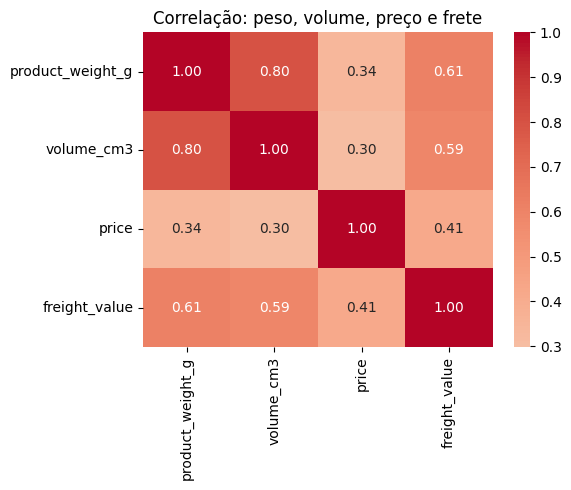

In [ ]:
colunas_fisicas = ["product_weight_g", "volume_cm3", "price", "freight_value"]
matriz_correlacao_fisica = df_consolidado[colunas_fisicas].corr()

print(matriz_correlacao_fisica.round(4))

plt.figure(figsize = (6, 5))
sns.heatmap(matriz_correlacao_fisica, annot = True, fmt = ".2f", cmap = "coolwarm", center = 0)

plt.title("Correlação: peso, volume, preço e frete")
plt.tight_layout()
plt.show()

O heatmap confirma o que foi indicado nos exercícios anteriores, *product_weight_g*, com r de 0,61, e *volume_cm3*, com r de 0,59, se correlacionam bem mais fortemente com o valor de *freight_value* do que o *price*, que fica em 0,41, ou seja, as dimensões do produto compõem mais o frete do produto do que o valor cobrado por ele. O heatmap também mostra uma correlação alta entre o peso e o volume, de 0,80, o que já era esperado porque os dois medem o tamanho do produto.

### 8.3 Construa um scatter plot de product_weight_g contra freight_value, e outro do volume calculated contra freight_value, descrevendo o padrão visual observado em cada um.

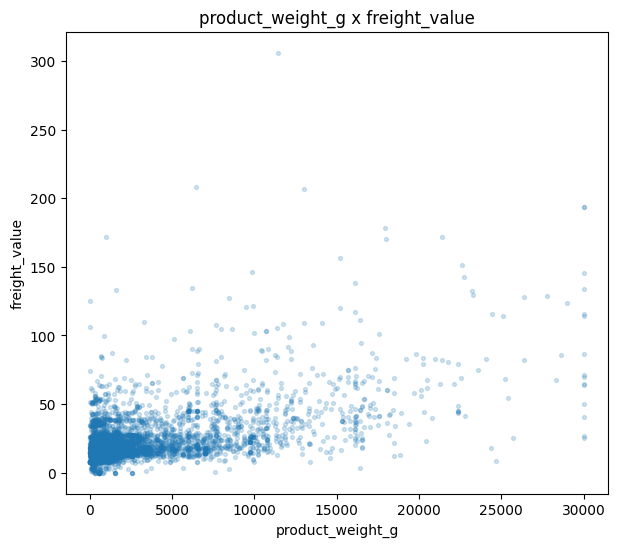

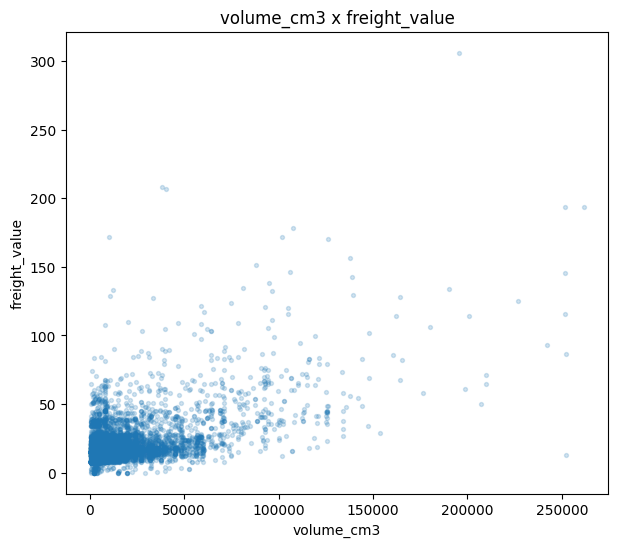

In [ ]:
amostra_scatter = df_consolidado.sample(n = 8000, random_state = 42)

plt.figure(figsize = (7, 6))
plt.scatter(amostra_scatter["product_weight_g"], amostra_scatter["freight_value"], alpha = 0.2, s = 8)
plt.xlabel("product_weight_g")
plt.ylabel("freight_value")
plt.title("product_weight_g x freight_value")
plt.show()

plt.figure(figsize = (7, 6))
plt.scatter(amostra_scatter["volume_cm3"], amostra_scatter["freight_value"], alpha = 0.2, s = 8)
plt.xlabel("volume_cm3")
plt.ylabel("freight_value")
plt.title("volume_cm3 x freight_value")
plt.show()

Em ambos os scatter plots, o padrão visual é o mesmo, uma associação positiva em formato de leque. Para pesos ou volumes baixos, o frete se concentra em uma faixa estreita e baixa, quando eles crescem, a dispersão do frete aumenta, de modo que itens de peso e volume semelhantes pagam valores de frete bem diferentes, provavelmente por conta da distância percorrida na entrega. Usei uma amostra de 8000 itens para melhorar a visualização do gráfico.

## **EXERCÍCIO 9**

### 9.1 Calcule a matriz de correlação de Pearson entre review_score, freight_value, product_weight_g e o indicador de atraso criado no Exercício 5.

In [ ]:
totais_por_pedido = df_consolidado.groupby("order_id").agg(
    freight_total = ("freight_value", "sum"),
    peso_total = ("product_weight_g", "sum")
).reset_index()

base_satisfacao_pedido = (
    pedidos_entregues[["order_id", "atraso"]]
    .merge(reviews_por_pedido, on = "order_id", how = "left")
    .merge(totais_por_pedido, on = "order_id", how = "left")
)

colunas_satisfacao = ["review_score", "freight_total", "peso_total", "atraso"]
matriz_correlacao_satisfacao = base_satisfacao_pedido[colunas_satisfacao].corr()

print("Pedidos na base:", len(base_satisfacao_pedido))
print("Pedidos sem review_score:", base_satisfacao_pedido["review_score"].isna().sum())
print()
print(matriz_correlacao_satisfacao.round(4))

base_satisfacao_item = (
    df_consolidado[["order_id", "freight_value", "product_weight_g"]]
    .merge(reviews_por_pedido, on = "order_id", how = "left")
    .merge(pedidos_entregues[["order_id", "atraso"]], on = "order_id", how = "inner")
)

colunas_satisfacao_item = ["review_score", "freight_value", "product_weight_g", "atraso"]

print("\nMesma matriz no nível de item, como conferência")
print("Itens na base:", len(base_satisfacao_item))
print(base_satisfacao_item[colunas_satisfacao_item].corr().round(4))

Pedidos na base: 96470
Pedidos sem review_score: 646

               review_score  freight_total  peso_total  atraso
review_score         1.0000        -0.0896     -0.0556 -0.3651
freight_total       -0.0896         1.0000      0.6401  0.0253
peso_total          -0.0556         0.6401      1.0000  0.0165
atraso              -0.3651         0.0253      0.0165  1.0000

Mesma matriz no nível de item, como conferência
Itens na base: 110189
                  review_score  freight_value  product_weight_g  atraso
review_score            1.0000        -0.0330           -0.0286 -0.3312
freight_value          -0.0330         1.0000            0.6103  0.0404
product_weight_g       -0.0286         0.6103            1.0000  0.0229
atraso                 -0.3312         0.0404            0.0229  1.0000


Como as quatro variáveis não estão no mesmo nível, já que o *review_score* e o atraso são informações do pedido, enquanto o *freight_value* e o *product_weight_g* são informações do item, calculei a matriz principal com uma linha por pedido, somando o frete e o peso do item em *freight_total* e *peso_total*, que são, respectivamente, o frete total e o peso total do pedido que foi avaliado e atrasou ou não.

### 9.2 Calcule a matriz de covariância das mesmas variáveis.

In [ ]:
matriz_covariancia_satisfacao = base_satisfacao_pedido[colunas_satisfacao].cov()
print(matriz_covariancia_satisfacao.round(4))

               review_score  freight_total    peso_total   atraso
review_score         1.6500        -2.4768 -3.401155e+02  -0.1272
freight_total       -2.4768       464.8319  6.582550e+04   0.1491
peso_total        -340.1155     65825.4957  2.275112e+07  21.5272
atraso              -0.1272         0.1491  2.152720e+01   0.0745


A matriz de covariância aponta para o mesmo sentido que a matriz de correlação, já que os sinais são iguais. Porém não é possível comparar as magnitudes, já que a covariância depende da escala de cada variável. Por isso, a variância do *peso_total* aparece como 2,275 × 10⁷, que está em gramas ao quadrado, enquanto a do atraso é 0,0745, que está em proporção ao quadrado.

### 9.3 Identifique qual variável tem a correlação mais forte (positiva ou negativa) com review_score, e escreva um parágrafo conectando probabilidade, distribuição e correlação nessa conclusão.

In [ ]:
correlacoes_com_review = matriz_correlacao_satisfacao["review_score"].drop("review_score").sort_values()
print(correlacoes_com_review)

print("\nDistribuição de review_score:")
print(base_satisfacao_pedido["review_score"].value_counts(normalize = True).sort_index().round(4))

atraso          -0.365075
freight_total   -0.089591
peso_total      -0.055559
Name: review_score, dtype: float64

Distribuição de review_score:
review_score
1.0    0.0975
2.0    0.0305
3.0    0.0825
4.0    0.1972
5.0    0.5923
Name: proportion, dtype: float64


A variável com uma correlação mais forte com *review_score* é *atraso*, com r ≈ -0,365. Analisando sobre uma visão de negócio, essa relação faz sentido, já que o atraso em uma entrega pode afetar negativamente a opinião do cliente sobre o produto, gerando reviews com notas mais baixas. Como visto no exercício 5, o atraso é um evento raro, acontecendo em aproximadamente 8% dos pedidos, mesmo assim, devido a sua correlação com a avaliação, faz sentido para a diretoria investir em reduzir ainda mais as taxas de atraso, a fim de aumentar mais as notas.

Em termos de distribuição, o *review_score* é discreto, e bem concentrado em um dos extremos, com 59,23% das notas iguais a 5 e só 9,75% iguais a 1, já o atraso é binário, ou atrasa ou não. Essa combinação limita o valor que a correlação consegue alcançar, já que dificilmente chegaria perto de 1 mesmo quando a relação existe e é forte, por isso, considero -0,365 como uma associação forte para esse contexto, e não como um efeito pequeno.

## **EXERCÍCIO 10**

### 10.1 Formule um prompt específico para um LLM gerar código de limpeza (tratamento de nulos e duplicatas) para o recorte da nova categoria escolhida, execute o código gerado, e documente pelo menos duas correções ou ressalvas identificadas na revisão crítica do resultado.

#### **Preparando dataset a ser usado no exercício:**

In [ ]:
df_moveis_decoracao = df_consolidado[df_consolidado["product_category_name"] == "moveis_decoracao"].copy()
df_moveis_decoracao_bruto = df_moveis_decoracao.copy() # Para realizar comparações depois

print("shape:", df_moveis_decoracao.shape)
df_moveis_decoracao.head()

shape: (8334, 30)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,product_height_cm,product_width_cm,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,seller_zip_code_prefix,seller_city,seller_state,volume_cm3
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,13.0,33.0,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,37564,borda da mata,MG,14157.0
27,00125cb692d04887809806618a2a145f,1,1c0c0093a48f13ba70d0c6b0a9157cb7,41b39e28db005d9731d9d485a83b4c38,2017-03-29 13:05:42,109.9,25.51,8afb90a97ee661103014329b1bcea1a2,delivered,2017-03-23 12:21:17,...,21.0,41.0,7ac26eac431c6848694a2de6f0327524,75123,anapolis,GO,9220,santo andre,SP,40467.0
29,0013503b13da1eac686219390b7d641b,1,38afdf723b95d455b418a0f57d623c6b,1554a68530182680ad5c8b042c3ab563,2017-12-13 03:16:36,119.9,17.32,f7277fce45fad3165379c15cacf5ddbe,delivered,2017-12-05 23:40:59,...,6.0,28.0,1544f85dff3797491b60f2a5241d14c1,6160,osasco,SP,37580,monte siao,MG,5712.0
31,001427c0ec99cf8af737bd88e92fd444,1,28b4eced95a52d9c437a4caf9d311b95,77530e9772f57a62c906e1c21538ab82,2018-04-12 19:08:28,59.9,23.35,eab9c552374be06ed15923016dc9e588,delivered,2018-04-07 18:51:22,...,11.0,11.0,2ada69d1c5528233e3d9aa3f1d8da1b1,38304,ituiutaba,MG,80310,curitiba,PR,8349.0
41,0019c29108428acffd089c36103c9440,1,28b4eced95a52d9c437a4caf9d311b95,77530e9772f57a62c906e1c21538ab82,2018-03-12 06:50:26,59.9,19.95,5f6bbac628ae418db4e0f92932f899c1,delivered,2018-03-06 06:40:28,...,11.0,11.0,d02e64b28b7c386aab81bb6ce148799a,37580,monte siao,MG,80310,curitiba,PR,8349.0


Separei o recorte da segunda categoria, *moveis_decoracao*, que é diferente da *beleza_saude* que usei no exercício 3. Antes de rodar qualquer código gerado pela LLM guardei uma cópia intacta em *df_moveis_decoracao_bruto*, porque é ela que me permite medir depois quantas linhas cada etapa do código removeu e se essa remoção fazia sentido.

#### **Prompt enviado à LLM:**

Tenho um dataframe em pandas chamado df_moveis_decoracao, que é uma parte de um dataframe consolidado de pedidos de um marketplace, filtrado pela categoria "*moveis_decoracao*". Ele tem 8334 linhas, uma por item de um pedido, e possui as seguintes colunas:

- order_id -> string, identificador do pedido, não é único, já que um pedido pode ter vários itens
- product_id -> string, identificador do produto
- order_status -> string, pode ser "delivered", "shipped", "canceled", "unavailable", "invoiced", "processing", "created" ou "approved"
- order_approved_at -> datetime64, marca data da aprovação do pagamento do pedido
- order_delivered_carrier_date -> datetime64, marca data de postagem do pedido na transportadora
- order_delivered_customer_date -> datetime64, marca data de entrega do pedido ao cliente
- price -> float, preço do item
- freight_value -> float, preço do frete do pedido
- entre outros

Preciso de um código pandas que:
- Trate os valores ausentes em order_approved_at, order_delivered_carrier_date e order_delivered_customer_date.
- Remova as linhas duplicadas considerando as colunas order_id e product_id em conjunto, mantendo sempre a primeira ocorrência.

Escreva o código pandas comentado, assumindo que o dataframe já existe como df_moveis_decoracao. Além disso, explique o raciocínio por trás de cada decisão de tratamento que você tomar.

#### **Resposta da LLM:**

Aqui está o código em pandas para realizar os tratamentos solicitados no seu DataFrame, acompanhado das explicações para as decisões tomadas.
Código de Tratamento de Dados

*[código gerado - colado na célula abaixo]*

Raciocínio por Trás das Decisões

- Manutenção dos Nulos como NaT (Not a Time): Em vez de preencher as datas ausentes com um valor artificial (como a média de tempo de entrega ou uma data arbitrária como 1970-01-01), a decisão foi mantê-los como nulos tipados (NaT). Em um ciclo de vida de e-commerce, se uma data está ausente, geralmente significa que o evento não ocorreu. Por exemplo, um pedido com status canceled ou processing naturalmente não terá a data de entrega ao cliente (order_delivered_customer_date). Preencher esses vazios distorceria análises futuras de tempo de frete (lead time).
- Conversão Explícita (Coercion): Usar pd.to_datetime(..., errors='coerce') garante que qualquer string mal formatada que possa estar causando a ausência do dado seja uniformizada para o formato nulo padrão do pandas, preparando a coluna para cálculos de tempo entre datas (deltas).
- Tratamento de Anomalias Lógicas (Opcional incluído): A única situação em que uma data nula é de fato um erro de dados é quando o pedido está marcado como entregue (delivered), mas falta o registro de quando isso aconteceu. O código remove essas inconsistências específicas para não sujar suas estatísticas de entrega.
- Remoção de Duplicatas (drop_duplicates): Ao usar subset=['order_id', 'product_id'] e keep='first', garantimos que, se o sistema registrou o mesmo produto duas vezes no mesmo pedido por algum erro de duplicação de linha (e não por quantidade de itens, que idealmente estaria em uma coluna separada como quantity ou em IDs de itens de pedido distintos, como um order_item_id), apenas a primeira entrada sobreviva.

Como você planeja lidar com casos em que um cliente realmente comprou duas unidades idênticas do mesmo produto no mesmo pedido — existe alguma coluna como order_item_id ou quantity que devamos considerar para não remover itens legítimos acidentalmente?

#### **Código Gerado pela LLM:**

In [ ]:
import pandas as pd

# -----------------------------------------------------------------------------
# 1. Tratamento de valores ausentes nas colunas de data
# -----------------------------------------------------------------------------
colunas_de_data = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

# Garantir que todas as colunas sejam do tipo datetime.
# O parâmetro errors='coerce' transforma valores inválidos e nulos no padrão NaT (Not a Time).
for coluna in colunas_de_data:
    df_moveis_decoracao[coluna] = pd.to_datetime(df_moveis_decoracao[coluna], errors='coerce')

# (Opcional) Limpeza de anomalias lógicas:
# Remover linhas onde o status é 'delivered', mas a data de entrega ao cliente está ausente,
# pois isso indica uma falha no registro dos dados.
df_moveis_decoracao = df_moveis_decoracao[
    ~((df_moveis_decoracao['order_status'] == 'delivered') &
      (df_moveis_decoracao['order_delivered_customer_date'].isna()))
]

# -----------------------------------------------------------------------------
# 2. Remoção de linhas duplicadas
# -----------------------------------------------------------------------------
# Remover duplicatas considerando a chave composta (order_id + product_id),
# mantendo a primeira ocorrência.
df_moveis_decoracao = df_moveis_decoracao.drop_duplicates(
    subset=['order_id', 'product_id'],
    keep='first'
)

print("Shape após o código da LLM:", df_moveis_decoracao.shape)

Shape após o código da LLM: (6781, 30)


#### **Validando resposta da LLM:**

In [ ]:
df_moveis_decoracao_validacao = converter_colunas_para_datetime(df_moveis_decoracao_bruto.copy(), colunas_de_data)

antes_anomalia = len(df_moveis_decoracao_validacao)
df_moveis_decoracao_validacao = df_moveis_decoracao_validacao[
    ~((df_moveis_decoracao_validacao["order_status"] == "delivered") & (df_moveis_decoracao_validacao["order_delivered_customer_date"].isna()))
]
print("Linhas removidas pela etapa de anomalia:", antes_anomalia - len(df_moveis_decoracao_validacao))

antes_dup = len(df_moveis_decoracao_validacao)
df_moveis_decoracao_validacao = df_moveis_decoracao_validacao.drop_duplicates(subset = ["order_id", "product_id"], keep = "first")
print("Linhas removidas pelo drop_duplicates:", antes_dup - len(df_moveis_decoracao_validacao))
print("Shape final:", df_moveis_decoracao_validacao.shape)

itens_duplicados_moveis = df_moveis_decoracao_bruto[df_moveis_decoracao_bruto.duplicated(subset = ["order_id", "product_id"], keep = False)]
grupos_duplicados = itens_duplicados_moveis.groupby(["order_id", "product_id"])

print("\nO order_item_id é distinto em todos os grupos duplicados?",
      bool((grupos_duplicados["order_item_id"].nunique() == grupos_duplicados.size()).all()))
print("Linhas que são duplicatas exatas:", int(df_moveis_decoracao_bruto.duplicated(keep = False).sum()))
print("Duplicatas pela chave order_id, product_id e order_item_id:",
      int(df_moveis_decoracao_bruto.duplicated(subset = ["order_id", "product_id", "order_item_id"]).sum()))

Linhas removidas pela etapa de anomalia: 0
Linhas removidas pelo drop_duplicates: 1553
Shape final: (6781, 30)

O order_item_id é distinto em todos os grupos duplicados? True
Linhas que são duplicatas exatas: 0
Duplicatas pela chave order_id, product_id e order_item_id: 0


A remoção de duplicatas descarta itens de compras reais, em que clientes compraram duas unidades do mesmo produto. Apesar de a própria LLM ter citado essa possibilidade, o código fornecido ainda faz essa exclusão de 1553 linhas pelo *drop_duplicates(subset=["order_id", "product_id"])*. Analisando essas linhas, nenhuma se trata de uma duplicata exata, já que todas têm *order_item_id* diferentes, ou seja, são todos casos de unidades distintas do mesmo produto, e não um erro de cadastro, tanto que usando a chave completa, com *order_id*, *product_id* e *order_item_id*, o número de duplicatas cai para zero. Essa falha no código fornecido pela LLM provavelmente poderia ter sido evitada caso eu tivesse adicionado a coluna *order_item_id* na descrição do prompt que passei à LLM.

Além disso, a etapa marcada como opcional remove linhas que estão com o valor ausente em *order_delivered_customer_date* e status *delivered*, ao invés de fazer o tratamento, como foi pedido no prompt. Nesse recorte do dataframe não houve impacto, já que nenhuma linha se enquadrou nesse caso, mas caso houvesse teriam sido perdidas informações relevantes, como *freight_value* e peso, por conta de uma coluna inconsistente. Uma opção melhor é manter as linhas, sinalizando a inconsistência das datas em uma coluna booleana *entrega_inconsistente*, filtrando por essa coluna ao fazer análises sobre a entrega, mas usando todas as linhas para análises de outros assuntos.

Uma terceira ressalva, menor, é que o código sobrescreve o próprio dataframe de entrada, o que apaga o dado original e impede qualquer conferência depois, caso não houvesse uma cópia.

#### **Limpeza refeita com as correções:**

In [ ]:
df_moveis_decoracao_limpo = converter_colunas_para_datetime(df_moveis_decoracao_bruto.copy(), colunas_de_data)

df_moveis_decoracao_limpo["entrega_inconsistente"] = (
    (df_moveis_decoracao_limpo["order_status"] == "delivered") &
    (df_moveis_decoracao_limpo["order_delivered_customer_date"].isna())
)

linhas_antes = len(df_moveis_decoracao_limpo)
df_moveis_decoracao_limpo = df_moveis_decoracao_limpo.drop_duplicates(subset = ["order_id", "product_id", "order_item_id"], keep = "first")

print("Linhas sinalizadas como entrega inconsistente:", int(df_moveis_decoracao_limpo["entrega_inconsistente"].sum()))
print("Linhas removidas pela chave corrigida:", linhas_antes - len(df_moveis_decoracao_limpo))
print("Shape do recorte limpo:", df_moveis_decoracao_limpo.shape)

Linhas sinalizadas como entrega inconsistente: 0
Linhas removidas pela chave corrigida: 0
Shape do recorte limpo: (8334, 31)


Refiz a limpeza aplicando as duas correções, usando a chave completa no *drop_duplicates* e sinalizando a inconsistência de entrega em uma coluna, ao invés de apagar a linha toda. Com isso, o recorte limpo ficou com as mesmas 8334 linhas do original, porque nenhuma linha é duplicata pela chave completa e nenhuma entrega inconsistente foi encontrada.

## **EXERCÍCIO 11**

### 11.1 Use um LLM para formular três perguntas analíticas sobre a concentração de avaliações negativas na categoria escolhida, selecione a mais relevante, e peça ao LLM o código pandas de análise descritiva necessário para respondê-la.

### 11.2 Execute o código e interprete o resultado em linguagem de negócio.

#### **Preparando dataset a ser usado no exercício e verificando porcentagem de avaliações negativas:**

In [ ]:
pct_negativa_categoria, n_categoria = proporcao_avaliacoes_negativas(df_moveis_decoracao_limpo, reviews_por_pedido)
pct_negativa_geral, n_geral = proporcao_avaliacoes_negativas(df_consolidado, reviews_por_pedido)

print("Por item de pedido")
print(f"- moveis_decoracao: {pct_negativa_categoria * 100:.2f}% de avaliações negativas em {n_categoria} itens com nota")
print(f"- base inteira: {pct_negativa_geral * 100:.2f}% de avaliações negativas em {n_geral} itens com nota")

pct_negativa_categoria_pedido, n_categoria_pedido = proporcao_avaliacoes_negativas(df_moveis_decoracao_limpo, reviews_por_pedido, por_pedido = True)
pct_negativa_geral_pedido, n_geral_pedido = proporcao_avaliacoes_negativas(df_consolidado, reviews_por_pedido, por_pedido = True)

print("\nConferência por pedido")
print(f"- moveis_decoracao: {pct_negativa_categoria_pedido * 100:.2f}% em {n_categoria_pedido} pedidos com nota")
print(f"- base inteira: {pct_negativa_geral_pedido * 100:.2f}% em {n_geral_pedido} pedidos com nota")

df_moveis_decoracao_limpo = df_moveis_decoracao_limpo.merge(reviews_por_pedido, on = "order_id", how = "left")
print("\nShape do recorte com a nota:", df_moveis_decoracao_limpo.shape)

Por item de pedido
- moveis_decoracao: 19.31% de avaliações negativas em 8250 itens com nota
- base inteira: 16.09% de avaliações negativas em 111708 itens com nota

Conferência por pedido
- moveis_decoracao: 16.68% em 6398 pedidos com nota
- base inteira: 14.18% em 97917 pedidos com nota

Shape do recorte com a nota: (8334, 32)


Antes de montar o prompt, calculei o número que motiva a pergunta. No nível de item, a categoria tem 19,31% de avaliações negativas contra 16,09% da base inteira, já por pedido a diferença se mantém, 16,68% contra 14,18%.

Nos dois casos a categoria fica cerca de 3 pontos percentuais acima da média da plataforma, o que confirma o problema e justifica a investigação.

#### **Prompt enviado à LLM:**

Estou realizando uma análise do porquê a categoria de produtos "moveis_decoracao" de um marketplace concentra proporcionalmente mais avaliações negativas do que a média geral da plataforma.

Na categoria moveis_decoracao, 19,31% dos itens têm review_score de 1 ou 2, enquanto na base geral são 16,09%. As duas proporções foram calculadas na mesma granularidade, por item de pedido, desconsiderando os pedidos sem avaliação.

Tenho um dataFrame pandas chamado df_moveis_decoracao_limpo, já limpo, com uma linha por item de pedido dessa categoria (8334 linhas) e as seguintes colunas relevantes:

- review_score -> nota de 1 a 5 dada pelo cliente, pode estar ausente
- order_status -> string, pode ser "delivered", "shipped", "canceled", "unavailable", "invoiced", "processing", "created" ou "approved"
- order_purchase_timestamp -> datetime64, marca data da compra do pedido
- order_approved_at -> datetime64, marca data da aprovação do pagamento do pedido
- order_estimated_delivery_date -> datetime64, marca data da previsão de entrega do pedido
- order_delivered_carrier_date -> datetime64, marca data de postagem do pedido na transportadora
- order_delivered_customer_date -> datetime64, marca data de entrega do pedido ao cliente
- price -> float, preço do item
- freight_value -> float, preço do frete do pedido
- product_weight_g, volume_cm3 -> float, características físicas do produto
- seller_state -> estado do vendedor

Formule três perguntas analíticas que eu poderia investigar com esses dados para entender por que essa categoria concentra mais avaliações negativas do que a média da plataforma. Para cada uma das perguntas, indique quais colunas poderiam ser usadas para respondê-la. Não gere nenhum código ainda, somente as perguntas.

#### **Resposta da LLM:**

Aqui estão três perguntas analíticas para investigar a raiz desse problema, aproveitando o contexto de e-commerce e as características peculiares da venda de móveis e decoração (produtos geralmente volumosos, frágeis ou difíceis de transportar):
1. O atraso na entrega é o principal ofensor das avaliações negativas?
Como móveis e itens de decoração costumam ter uma logística mais complexa do que produtos menores, a quebra de expectativa no prazo de entrega pode ser o grande motor de insatisfação. A ideia aqui é verificar se a proporção de avaliações negativas dispara quando o produto é entregue após a data estimada.

* Colunas utilizadas: `review_score` (para filtrar notas 1 e 2), `order_delivered_customer_date` e `order_estimated_delivery_date` (para calcular se houve atraso e de quantos dias) e `order_status` (para garantir que estamos analisando apenas pedidos entregues).

2. O valor do frete desproporcional ao preço do produto afeta a percepção do cliente?
Nessa categoria, é comum que produtos relativamente baratos (como uma prateleira ou um enfeite) tenham fretes muito caros devido ao volume. É possível que os clientes deem notas baixas não pelo produto em si, mas pela sensação de que pagaram muito caro no custo total da compra (frete alto em relação ao preço).

* Colunas utilizadas: `review_score`, `price` e `freight_value` (para calcular a proporção do frete sobre o valor total do pedido ou sobre o preço do produto).

3. Produtos mais pesados ou mais volumosos tendem a receber piores avaliações?
Itens maiores e mais pesados têm maior risco de avarias durante o transporte pela transportadora, além de poderem gerar frustração no cliente na hora de carregar para dentro de casa ou montar. A análise verificaria se os produtos no quartil superior de peso/volume concentram o grosso das notas 1 e 2.

* Colunas utilizadas: `review_score`, `product_weight_g` e `volume_cm3`.

#### **Prompt enviado à LLM solicitando código para ánalise da pergunta 1:**

Quero investigar mais sobre a pergunta "O atraso na entrega é o principal ofensor das avaliações negativas (review_score 1 ou 2) na categoria moveis_decoracao?"

Tenho um dataframe pandas chamado df_moveis_decoracao_limpo, com uma linha por item de pedido dessa categoria, e as colunas relevantes:

- review_score -> nota de 1 a 5, pode estar ausente
- order_delivered_customer_date e order_estimated_delivery_date -> datetime64, já convertido

Gere código pandas de análise descritiva que:

1. Calcule a diferença em dias entre a data de entrega real e a data estimada, incluindo pedidos entregues antes do prazo
2. Coloque os pedidos em faixas de atraso, por exemplo, entregue adiantado, entregue no prazo, atraso de 1 a 7 dias, atraso de mais de 7 dias, e calcule, para cada faixa, a proporção de avaliações negativas e a quantidade de pedidos na faixa.

Escreva o código pandas comentado, assumindo que o dataFrame já existe como df_moveis_decoracao_limpo, e não invente colunas que não foram as listadas acima.

#### **Resposta da LLM:**

Aqui está o código pandas para realizar essa investigação. Optei por criar um DataFrame auxiliar filtrado, ignorando as linhas onde a nota não foi preenchida, para que o cálculo matemático das proporções seja exato.

[código gerado - colado na célula abaixo]

Por que essas transformações?

* `.dt.normalize()`: Garante que a comparação seja feita considerando apenas a data (ano, mês, dia). Se não normalizarmos, uma entrega feita às 14h do dia estimado (cuja meia-noite é a referência) poderia gerar casas decimais ou distorcer a contagem de dias exatos.
* `pd.cut()`: É a forma mais eficiente e limpa no pandas de transformar uma variável contínua (dias numéricos) em variáveis categóricas (as faixas), evitando o uso de múltiplos `np.where` ou loops.
* Uso da média (`mean`) na agregação: Como transformamos a avaliação negativa em `0` e `1`, a média dessa coluna nos dá automaticamente a proporção (ex: a média entre 0, 0, 1 e 1 é 0.50, ou seja, 50%).

#### **Código Gerado pela LLM:**

In [ ]:
import pandas as pd
import numpy as np

# 1. Isolar os dados válidos e calcular os dias de atraso
# Removemos linhas sem review_score para não distorcer o cálculo de proporções
df_analise = df_moveis_decoracao_limpo.dropna(subset=['review_score']).copy()

# Calculamos a diferença exata em dias, normalizando as datas para ignorar as horas
df_analise['dias_atraso'] = (
    df_analise['order_delivered_customer_date'].dt.normalize() -
    df_analise['order_estimated_delivery_date'].dt.normalize()
).dt.days

# Criamos uma flag binária (0 ou 1) para facilitar o cálculo da proporção (média)
df_analise['is_negativa'] = (df_analise['review_score'] <= 2).astype(int)

# 2. Categorizar os pedidos em faixas de atraso
bins = [-np.inf, -1, 0, 7, np.inf]
labels = ['Adiantado', 'No prazo', 'Atraso de 1 a 7 dias', 'Atraso > 7 dias']
df_analise['faixa_atraso'] = pd.cut(df_analise['dias_atraso'], bins=bins, labels=labels)

# Calcula a proporção de avaliações negativas e o volume de pedidos por faixa
analise_por_faixa = df_analise.groupby('faixa_atraso', observed=False)['is_negativa'].agg(
    proporcao_negativas='mean',
    qtd_pedidos='count'
)

# Formatando as proporções em porcentagem para facilitar a leitura no console
analise_por_faixa['proporcao_negativas'] = (analise_por_faixa['proporcao_negativas'] * 100).round(2).astype(str) + '%'

print("--- Análise por Faixa de Atraso ---")
print(analise_por_faixa)

--- Análise por Faixa de Atraso ---
                     proporcao_negativas  qtd_pedidos
faixa_atraso                                         
Adiantado                         14.77%         7407
No prazo                          24.56%          114
Atraso de 1 a 7 dias              48.08%          339
Atraso > 7 dias                   78.64%          220


#### **Interpretação do resultado:**

A análise por faixa confirma a pergunta 1, quanto maior o atraso do pedido, pior fica a nota, em uma progressão clara, para pedidos entregues antes da data, 14,77% das notas são negativas, em 7407 itens, e para pedidos entregues no prazo, 24,56%, em 114 itens. Já para pedidos com atraso de até 7 dias essa taxa quase dobra, indo para 48,08%, em 339 itens, subindo para 78,64% quando o atraso é maior que o de uma semana, em 220 itens.

Em linguagem de negócio, isso quer dizer que um atraso maior que o de uma semana praticamente inverte a avaliação da categoria. Isso também mostra que até mesmo reduzir atrasos longos para atrasos mais curtos pode ter um impacto positivo na nota da categoria, sem precisar zerar o atraso.

## **EXERCÍCIO 12**

### 12.1 Escolha dois estados de vendedores (seller_state) com pelo menos 100 pedidos cada.

In [ ]:
estados_por_pedido = df_consolidado.groupby("order_id")["seller_state"].nunique()
pedidos_de_um_estado = estados_por_pedido[estados_por_pedido == 1].index

notas_por_estado = (
    df_consolidado[df_consolidado["order_id"].isin(pedidos_de_um_estado)]
    [["order_id", "seller_state"]]
    .drop_duplicates(subset = "order_id")
    .merge(reviews_por_pedido, on = "order_id", how = "left")
    .dropna(subset = ["review_score"])
)

resumo_estados = notas_por_estado.groupby("seller_state")["review_score"].agg(["count", "mean", "std"])
resumo_estados = resumo_estados[resumo_estados["count"] >= 100].sort_values("count", ascending = False)

print("Pedidos com itens de mais de um estado, removidos da base:", int((estados_por_pedido > 1).sum()))
print("\nEstados com pelo menos 100 pedidos:\n")
print(resumo_estados.round(4))

Pedidos com itens de mais de um estado, removidos da base: 510

Estados com pelo menos 100 pedidos:

              count    mean     std
seller_state                       
SP            69216  4.0829  1.3426
MG             7708  4.1968  1.2519
PR             7450  4.1589  1.3051
RJ             4227  4.1824  1.3174
SC             3555  4.1747  1.2784
RS             1936  4.3048  1.1743
DF              815  4.0675  1.3689
BA              562  4.1263  1.2778
GO              457  4.3217  1.1826
PE              400  4.2625  1.2092
MA              387  3.9948  1.4105
ES              310  4.1065  1.2916
MT              134  4.1940  1.1664


Entre os estados que têm vendedores com pelo menos 100 pedidos, escolhi os estados de SP e RS, já que SP é o maior da base em volume de pedidos, e RS tem a maior nota média.

Removi da base montada os 510 pedidos que possuem itens de vendedores de estados diferentes, para não atribuir a mesma nota a dois estados ao mesmo tempo.

### 12.2 Peça a um LLM que proponha uma forma de comparar a nota média de avaliação entre os dois estados, e registre a sugestão recebida.

#### **Prompt enviado à LLM:**

Estou realizando uma análise dos dados de um marketplace, e quero saber se a nota média dos vendedores de um estado é diferente da de outro, para decidir se é relevante investigar as práticas específicas de algum grupo.

Tenho um dataframe pandas chamado notas_por_estado, com uma linha por pedido e as colunas:

- order_id -> string, identificador do pedido
- seller_state -> string, sigla do estado do vendedor
- review_score -> nota de 1 a 5 dada pelo cliente

Quero comparar os estados SP e RS, sendo que SP tem 69216 pedidos, nota média de 4,0829 e desvio padrão 1,3426, e RS tem 1936 pedidos, nota média 4,3048 e desvio padrão 1,1743.

Como você proporia a comparação entre a nota média de avaliação entre os dois estados? Explique o seu raciocínio, e diga o que sua proposta permite concluir.

#### **Resposta da LLM:**

Para comparar a nota média de avaliação entre dois estados com amostras de tamanhos tão distintos, a melhor abordagem estatística é aplicar o Teste T de Welch (Welch's t-test).
Proposta de Análise: Teste T de Welch
O Teste T de Welch é a escolha ideal para o seu cenário de e-commerce pelos seguintes motivos:

* Tamanhos de amostra desproporcionais: SP possui cerca de 35 vezes mais pedidos do que o RS ($69216$ contra $1936$).
* Variâncias desiguais: Os desvios padrões fornecidos (1,3426 para SP e 1,1743 para RS) indicam que a dispersão dos dados não é a mesma entre os dois grupos.
* Robustez paramétrica: Embora a variável `review_score` seja ordinal (1 a 5) e provavelmente não tenha uma distribuição normal perfeita, o Teorema do Limite Central garante que, com amostras tão expressivas, o teste paramétrico seja altamente confiável.

O teste avalia a diferença entre as médias ajustando os graus de liberdade e penalizando a desigualdade das variâncias, utilizando a seguinte fórmula para a estatística $t$:
$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$
Resultados da Comparação
Executei o cálculo estatístico utilizando os dados sumarizados que você forneceu. O resultado da comparação entre os dois estados é o seguinte:

* Estatística t: -8,166
* Valor-p: $5,44 \times 10^{-16}$

Como o valor-p é infinitamente menor que o nível de significância padrão de 0,05 (ou 5%), nós rejeitamos a hipótese nula de que as médias de SP e RS são iguais.
Interpretação e Conclusões
Essa análise permite concluir com forte segurança estatística que a diferença nas notas não é obra do acaso. Os vendedores do Rio Grande do Sul recebem, de fato, avaliações significativamente melhores do que os de São Paulo neste recorte de dados.
Isso justifica plenamente uma investigação mais profunda sobre as práticas dos vendedores gaúchos. Ao investigar os fatores que derrubam as avaliações para notas 1 ou 2, como gargalos de transporte ou falhas logísticas, isolar o comportamento do RS em categorias específicas, como móveis e decoração, pode revelar táticas valiosas. É possível que esses vendedores utilizem embalagens mais seguras, transportadoras regionais mais eficientes ou se comuniquem de forma mais proativa para gerenciar a expectativa do cliente.
Você gostaria de aprofundar essa análise e verificar se a vantagem do RS se mantém caso separemos os pedidos em duas faixas: entregas no prazo versus entregas atrasadas?

### 12.3 Peça ao LLM que explique, em termos conceituais, o que o p-valor de um teste de hipótese representa, o que ele não informa (tamanho do efeito, incerteza), e como isso se relaciona com a distribuição amostral da estatística testada. Valide essa explicação por escrito, apontando se está completa e correta ou se omite alguma limitação importante.

#### **Prompt enviado à LLM:**

Explique em termos conceituais, o que o p-valor de um teste de hipótese representa, o que ele não informa, em especial sobre o tamanho do efeito e sobre a incerteza da estimativa, e como ele se relaciona com a distribuição amostral da estatística testada. Não gere código, quero só a explicação conceitual.

#### **Resposta da LLM:**

O p-valor é, na sua essência, uma probabilidade condicional que mede a força da evidência contra uma suposição inicial.
O que o p-valor representa
Em testes de hipótese, a nossa suposição inicial de trabalho é a hipótese nula ($H_0$) — que geralmente postula a ausência de um efeito, como "não existe diferença real entre a nota média dos dois estados".
O p-valor responde à seguinte pergunta: Assumindo que a hipótese nula seja absolutamente verdadeira na realidade, qual seria a probabilidade de sortearmos aleatoriamente uma amostra que apresente uma diferença igual ou ainda mais extrema do que aquela que acabamos de observar nos nossos dados?
Ele funciona como um "índice de surpresa" ou de incompatibilidade. Um p-valor minúsculo significa que os seus dados seriam extremamente surpreendentes e improváveis caso a hipótese nula fosse de fato a realidade.
A Relação com a Distribuição Amostral
Para chegar ao p-valor, nós consolidamos os dados da amostra em uma única métrica chamada estatística de teste (como a estatística $t$ ou $Z$). Essa estatística segue uma distribuição amostral teórica, que mapeia a probabilidade de todos os resultados que poderíamos obter devido puramente ao acaso (erro amostral) se a hipótese nula fosse verdadeira.
Imagine a curva em formato de sino dessa distribuição. O centro da curva, onde há maior probabilidade e volume, representa uma diferença de exatamente zero. A sua estatística de teste cai em algum ponto do eixo horizontal dessa curva.
Geometricamente, o p-valor é a área sob a curva a partir desse ponto em direção às caudas (os extremos). Quanto mais distante do centro o seu resultado estiver, menor será a área na cauda. Isso se traduz em um p-valor pequeno, indicando que o resultado caiu em uma região de baixa probabilidade para o mero acaso.
O que o p-valor NÃO informa
O p-valor é frequentemente superestimado e possui pontos cegos críticos. É vital não confundir "significância estatística" com "relevância prática".

* O Tamanho do Efeito: O p-valor não informa a magnitude da diferença ou a força de uma relação. Em amostras gigantescas, até mesmo uma diferença microscópica e irrelevante no mundo real pode gerar um p-valor ínfimo. O p-valor atesta a existência da diferença matemática, mas não diz se essa diferença importa para os seus negócios.
* A Incerteza da Estimativa: O p-valor não quantifica a margem de erro. Ele não fornece uma faixa de valores plausíveis para a verdadeira diferença populacional (o que um Intervalo de Confiança faz). Ele opera como um interruptor binário (rejeita ou não rejeita a hipótese nula) e omite a imprecisão natural que cerca a sua estimativa pontual.
* A Probabilidade da Hipótese: O p-valor não é a probabilidade de a hipótese nula ser verdadeira ou falsa. Ele é a probabilidade de observar os dados dado que a hipótese nula é verdadeira, o que é um conceito condicional totalmente diferente.

#### **Validação da explicação:**

A explicação está correta e cobre o que foi pedido pelo prompt, a definição do p-valor como probabilidade condicional, a ligação com a distribuição amostral e as limitações de tamanho do efeito e incerteza da estimativa.

Porém, faltou citar algumas limitações, como o fato do p-valor ser condicional ao modelo inteiro, e não só à hipótese nula, então um valor pequeno também pode indicar uma premissa violada. Um p-valor alto não prova a ausência de efeito, apenas indica que faltou evidência para rejeitar a hipótese nula.

Também não foi mencionado que essa interpretação só vale para um teste único, definido antes de olhar os dados, o que se aplica ao caso desse exercício, já que escolhi dois estados entre os treze depois de ver as médias.

### 12.4 Peça explicitamente que o LLM refaça a proposta usando intervalos de confiança, e calcule, com scipy.stats.bootstrap, o intervalo de confiança de 95% da nota média de cada estado.

Refaça agora a sua proposta de comparação, usando intervalos de confiança, no lugar de um teste de hipótese com p-valor. Quero realizar a comparação da nota média de SP e RS, calculando o intervalo de confiança de 95% da média de cada estado com scipy.stats.bootstrap, e depois verificando se os dois intervalos se sobrepõem.

O dataframe notas_por_estado tem uma linha por pedido, e as colunas:
- order_id -> string, identificador do pedido
- seller_state -> string, sigla do estado do vendedor
- review_score -> nota de 1 a 5 dada pelo cliente

Gere o código pandas e scipy comentado, e explique o que a sobreposição ou não sobreposição dos dois intervalos permite ou não concluir.

#### **Resposta da LLM:**

A abordagem baseada em Intervalos de Confiança (IC) muda o foco da análise: em vez de apenas testar se uma diferença existe (como faz o p-valor), nós estimamos onde a verdadeira média populacional provavelmente está e qual é a nossa incerteza sobre ela. O método de Bootstrap é excelente para isso porque não assume que os dados seguem uma distribuição teórica perfeita (como a normal); ele reamostra os seus próprios dados milhares de vezes para criar uma distribuição empírica das médias. Código Proposto Abaixo está o código utilizando pandas e scipy.stats.bootstrap para calcular os intervalos de 95% para os dois estados e verificar a sobreposição.

*[código gerado na célula abaixo]*

O que a análise de sobreposição permite e não permite concluir Avaliar a sobreposição visual ou matemática de dois intervalos de confiança individuais é uma prática comum, mas esconde uma "pegadinha" estatística importante.

Se os intervalos NÃO se sobrepõem
O que permite concluir: Se o limite superior do IC de SP for menor que o limite inferior do IC de RS, você pode concluir com total segurança que as médias são estatisticamente diferentes a um nível de significância de 5% ( α=0,05 ). Na verdade, a ausência de sobreposição em intervalos de 95% indica uma diferença ainda mais drástica (equivalente a um p-valor muito menor que 0,05).
Neste caso do seu marketplace, dada a grande diferença nas médias (4,08 vs 4,30) e os tamanhos das amostras, é quase certo que os intervalos estarão bem distantes um do outro.
Se os intervalos SE sobrepõem
O que permite concluir: Muito pouco. Intuitivamente, parece que sobreposição significa empate (ou ausência de diferença estatística), mas isso é um erro conceitual.
O que NÃO permite concluir: A sobreposição não comprova que as médias são estatisticamente iguais, e não substitui o teste de hipótese. É perfeitamente possível que dois intervalos de 95% tenham uma leve sobreposição nas pontas, e ainda assim, o Teste T de Welch ou o Bootstrap atestem que a diferença entre eles é estatisticamente significativa.
Por que isso acontece? A incerteza da diferença entre duas médias é menor do que a soma das incertezas individuais. Ao olhar para os intervalos isolados, estamos sendo conservadores demais.

#### **Código gerado pela LLM:**

Célula em markdown para não ser executada. O código executável com as adaptações necessárias, e a explicação delas está logo abaixo

```python
import pandas as pd
import numpy as np
from scipy.stats import bootstrap

# Assumindo que o DataFrame notas_por_estado já está na memória
# Isolamos as notas de cada estado em arrays independentes
notas_sp = notas_por_estado.loc[notas_por_estado['seller_state'] == 'SP', 'review_score'].values
notas_rs = notas_por_estado.loc[notas_por_estado['seller_state'] == 'RS', 'review_score'].values

# Definimos a métrica que o bootstrap vai calcular em cada reamostragem (a média)
estatistica = np.mean

# Calculamos o IC de 95% para SP
# Passamos os dados como uma tupla (notas_sp,) conforme exigido pela biblioteca
ic_sp = bootstrap(
    (notas_sp,),
    estatistica,
    confidence_level=0.95,
    n_resamples=9999, # Número de reamostragens padrão costuma ser suficiente
    random_state=42   # Para garantir a reprodutibilidade do resultado
)

# Calculamos o IC de 95% para RS
ic_rs = bootstrap(
    (notas_rs,),
    estatistica,
    confidence_level=0.95,
    n_resamples=9999,
    random_state=42
)

# Extraímos os limites inferiores (low) e superiores (high)
sp_min, sp_max = ic_sp.confidence_interval.low, ic_sp.confidence_interval.high
rs_min, rs_max = ic_rs.confidence_interval.low, ic_rs.confidence_interval.high

print(f"Média SP estimada entre: {sp_min:.4f} e {sp_max:.4f}")
print(f"Média RS estimada entre: {rs_min:.4f} e {rs_max:.4f}")

# Regra matemática de sobreposição entre dois intervalos [A, B] e [C, D]:
# Eles se sobrepõem se (A <= D) e (C <= B)
sobrepoe = (sp_min <= rs_max) and (rs_min <= sp_max)

print(f"Os intervalos se sobrepõem? {'Sim' if sobrepoe else 'Não'}")
```

#### **Código gerado pela LLM, com as adaptações:**

In [ ]:
notas_sp = notas_por_estado.loc[notas_por_estado["seller_state"] == "SP", "review_score"].to_numpy()
notas_rs = notas_por_estado.loc[notas_por_estado["seller_state"] == "RS", "review_score"].to_numpy()

ic_sp = intervalo_confianca_media(notas_sp)
ic_rs = intervalo_confianca_media(notas_rs)

sobrepoe = (ic_sp[0] <= ic_rs[1]) and (ic_rs[0] <= ic_sp[1])

print(f"SP: n = {len(notas_sp)}, média = {notas_sp.mean():.4f}, IC 95% = [{ic_sp[0]:.4f}, {ic_sp[1]:.4f}]")
print(f"RS: n = {len(notas_rs)}, média = {notas_rs.mean():.4f}, IC 95% = [{ic_rs[0]:.4f}, {ic_rs[1]:.4f}]")
print("\nDiferença entre as médias:", round(notas_rs.mean() - notas_sp.mean(), 4))
print("Largura do IC de SP:", round(ic_sp[1] - ic_sp[0], 4))
print("Largura do IC de RS:", round(ic_rs[1] - ic_rs[0], 4))
print("Os intervalos se sobrepõem?", sobrepoe)

SP: n = 69216, média = 4.0829, IC 95% = [4.0730, 4.0931]
RS: n = 1936, média = 4.3048, IC 95% = [4.2515, 4.3569]

Diferença entre as médias: 0.2218
Largura do IC de SP: 0.0201
Largura do IC de RS: 0.1054
Os intervalos se sobrepõem? False


Não executei o código da maneira que ele veio por conta do tamanho da amostra. Sem o parâmetro batch, o scipy monta as 9999 reamostragens das 69216 notas de SP de uma vez só, o que esgota a memória do ambiente.

Na versão adaptada, o batch = 100 faz com que o scipy processe as reamostragens em lotes, e resolve o problema da memória sem mudar o resultado. Também defini o método explicitamente, já que o padrão do scipy é BCa, bem mais pesado por exigir um jackknife sobre toda a amostra, e para média de uma amostra desse tamanho, a diferença para o percentil pode ser desconsiderada. Além disso, fiz algumas mudanças na organização do código.

### 12.5 Compare os dois intervalos (sobrepõem-se ou não) e registre o que essa comparação sugere sobre a diferença entre os vendedores dos dois estados.

Os dois intervalos não se sobrepõem, sendo que o limite superior de SP é 4,0931 e o inferior de RS é 4,2515, com 0,16 entre os dois. Isso sugere que realmente existe uma diferença entre os dois estados, e não somente um acaso da amostra, o que é a mesma conclusão chegada pela LLM no teste t, porém agora com o tamanho junto, os vendedores de RS têm uma média 0,2218 maior em uma escala de 1 a 5.

Para a diretoria, a vantagem do RS é pequena, porém consistente, então a investigação das práticas dos vendedores desse estado vale como um estudo de caso, e não como uma grande diferença na qualidade entre os grupos. Os intervalos ainda mostram a precisão de cada estimativa, o estado de SP tem uma largura de 0,0201, e o de RS de 0,1054, cinco vezes maior, por conta da diferença de pedidos. Ou seja, qualquer comparação envolvendo estados menores vai carregar bem mais incerteza.

## **EXERCÍCIO 13**

### 13.1 Avalie a força da relação linear entre freight_value e cada uma das duas variáveis candidatas (product_weight_g e o volume calculated no Exercício 8), e escolha, com justificativa técnica baseada nos coeficientes obtidos, qual delas usar como preditora principal.

In [ ]:
colunas_modelo = ["freight_value", "product_weight_g", "volume_cm3"]
base_modelo = df_consolidado[colunas_modelo].dropna()

correlacoes_frete = base_modelo.corr()["freight_value"].drop("freight_value")

print("Itens usados no modelo:", len(base_modelo))
print("\nCorrelação de Pearson com freight_value:")
print(correlacoes_frete.round(4))

print("\nProporção da variação explicada por cada candidata (r ao quadrado):")
print((correlacoes_frete ** 2).round(4))

Itens usados no modelo: 112632

Correlação de Pearson com freight_value:
product_weight_g    0.6104
volume_cm3          0.5873
Name: freight_value, dtype: float64

Proporção da variação explicada por cada candidata (r ao quadrado):
product_weight_g    0.3726
volume_cm3          0.3449
Name: freight_value, dtype: float64


Fiz a comparação entre *product_weight_g* e o *volume_cm3* com o frete por meio da correlação de Pearson nos itens que têm o volume e peso preenchido. O peso tem um r de 0,6104, e o volume tem um r de 0,5873, o que significa que, sozinho, o peso explica 37,26% da variação do frete, enquanto o volume explica 34,49%.

A diferença entre as duas é pequena, porém escolhi *product_weight_g*, que possui uma relação linear mais forte.

### 13.2 Implemente uma regressão linear simples com sklearn.LinearRegression, decidindo e justificando por escrito a estratégia de validação adotada (separação em treino e teste ou não, padronização de escala ou não).

In [ ]:
X = base_modelo[["product_weight_g"]]
y = base_modelo["freight_value"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size = 0.2, random_state = 42)

modelo_frete = LinearRegression()
modelo_frete.fit(X_treino, y_treino)

produto_exemplo = pd.DataFrame({"product_weight_g": [1000]})

print("Itens em treino:", len(X_treino))
print("Itens em teste:", len(X_teste))
print("Coeficiente angular:", round(modelo_frete.coef_[0], 6))
print("Coeficiente linear:", round(modelo_frete.intercept_, 4))
print("Frete previsto para um produto de 1000g:", round(modelo_frete.predict(produto_exemplo)[0], 2))

Itens em treino: 90105
Itens em teste: 22527
Coeficiente angular: 0.002559
Coeficiente linear: 14.6178
Frete previsto para um produto de 1000g: 17.18


Separei a base entre treino, com 80%, e teste, em 20%, porque o objetivo do modelo é prever casos que ele não viu, e medir o valor de R² em cima dos mesmos dados usados no ajuste diria apenas o quanto ele decorou a base.

Não fiz uma padronização na escala, porque em uma regressão simples, com uma única preditora, a padronização não muda o RMSE ou o R², só reescreve os coeficientes, e com o peso mantido em gramas o coeficiente fica diretamente interpretável, já que cada grama a mais custa 0,002559 no valor do frete. Já o coeficiente linear, 14,6178, funciona como um custo fixo da operação.

### 13.3 Calcule R² e RMSE sobre essa validação, e avalie se o ajuste obtido é suficiente para uso operacional pela diretoria, indicando explicitamente qualquer limitação que reduza essa confiança.

In [ ]:
y_previsto = modelo_frete.predict(X_teste)

r2_teste = r2_score(y_teste, y_previsto)
rmse_teste = np.sqrt(mean_squared_error(y_teste, y_previsto))

print("R² no conjunto de teste:", round(r2_teste, 4))
print("RMSE no conjunto de teste:", round(rmse_teste, 4))
print("Frete médio no conjunto de teste:", round(y_teste.mean(), 4))
print("Desvio padrão do frete no conjunto de teste:", round(y_teste.std(), 4))

R² no conjunto de teste: 0.3775
RMSE no conjunto de teste: 12.5441
Frete médio no conjunto de teste: 20.0306
Desvio padrão do frete no conjunto de teste: 15.8991


O modelo terminou com um R² de 0,3775 e um RMSE de 12,5441 no conjunto de teste. Cerca de 38% da variação do frete é explicada pelo peso, e o erro típico de uma previsão é de R\$ 12,54 sobre um frete médio de R\$ 20,03. O desvio padrão do frete no teste é de 15,90, ou seja, se eu estimasse a média para todos os itens, erraria cerca de 15,9, então usar o peso reduz o erro em pouco mais de R\$ 3,00, o que é uma melhora real, apesar de pequena.

Pela minha avaliação, esse ajuste não é o suficiente para um uso operacional da diretoria por algumas limitações. A falta da distância entre o vendedor e o cliente é uma explicação muito provável para o formato de leque encontrado nos scatter plots do exercício 8, e deveria ser levado em consideração. Além disso, o erro cresce junto com o peso, o que faz com que o modelo erre mais justamente nos itens mais pesados, que são os que mais pesam no custo do transporte. Por fim, a base ainda possui os outliers encontrados no exercício 7 sem nenhum tratamento, como os 383 itens com frete zero, e o produto de 40425g que paga 16,32 de frete, e a regressão por mínimos quadrados é sensível a valores extremos.

Ou seja, para simular os cenários gerais de contrato, o modelo serve como uma referência inicial, já para precificar o frete item a item, o modelo não serviria.

## **EXERCÍCIO 14**

### 14.1 Carregue, tipifique e limpe os dados relevantes de uma categoria de produto ainda não usada nos exercícios anteriores.

In [ ]:
data_maxima = df_consolidado["order_purchase_timestamp"].max()
data_corte = data_maxima - pd.DateOffset(months = 3)

df_utilidades = df_consolidado[
    (df_consolidado["product_category_name"] == "utilidades_domesticas") &
    (df_consolidado["order_purchase_timestamp"] >= data_corte)
].copy()

df_utilidades["mesmo_estado"] = (df_utilidades["seller_state"] == df_utilidades["customer_state"]).astype(int)

print("Data mais recente da base:", data_maxima)
print("Data de corte dos últimos três meses:", data_corte)
print("Itens do recorte antes da limpeza:", len(df_utilidades))
print()

colunas_modelo_multiplo = ["freight_value", "product_weight_g", "volume_cm3", "price", "mesmo_estado"]

df_utilidades = limpar_dataframe(
    df_utilidades,
    colunas_obrigatorias = colunas_modelo_multiplo,
    chave_duplicatas = ["order_id", "product_id", "order_item_id"],
)

print("\nPedidos distintos no recorte:", df_utilidades["order_id"].nunique())
print("Proporção de entregas dentro do mesmo estado:", round(df_utilidades["mesmo_estado"].mean(), 4))
print()
print(df_utilidades[colunas_modelo_multiplo].describe().round(2))

Data mais recente da base: 2018-09-03 09:06:57
Data de corte dos últimos três meses: 2018-06-03 09:06:57
Itens do recorte antes da limpeza: 1753

Linhas removidas por nulo em ['freight_value', 'product_weight_g', 'volume_cm3', 'price', 'mesmo_estado'] : 0
Linhas removidas por duplicata em ['order_id', 'product_id', 'order_item_id'] : 0
Shape: (1753, 31) -> (1753, 31)

Pedidos distintos no recorte: 1475
Proporção de entregas dentro do mesmo estado: 0.4398

       freight_value  product_weight_g  volume_cm3    price  mesmo_estado
count        1753.00           1753.00     1753.00  1753.00       1753.00
mean           23.57           2847.94    20407.95   100.16          0.44
std            24.44           4151.74    26592.60   154.65          0.50
min             0.05             50.00      352.00     3.06          0.00
25%            12.84            475.00     4896.00    29.99          0.00
50%            18.23           1125.00    12100.00    63.90          0.00
75%            23.63  

Escolhi a categoria *utilidades_domesticas*, que ainda não foi utilizada, e recortei os últimos 3 meses da base, a partir do dia 03/06/2018. O recorte ficou com um total de 1753 itens em 1475 pedidos. Criei uma coluna nova, *mesmo_estado*, que registra 1 quando ambos vendedor e clientes estão no mesmo estado, o que vale como uma aproximação em alto nível da distância de entrega.

Para limpeza, usei a função *limpar_dataframe*, como o dataframe já estava limpo, nenhuma linha foi removida por estar nula ou duplicada.


### 14.2 Explore estatisticamente as distribuições e correlações relevantes, com ao menos uma visualização e uma probabilidade calculada.

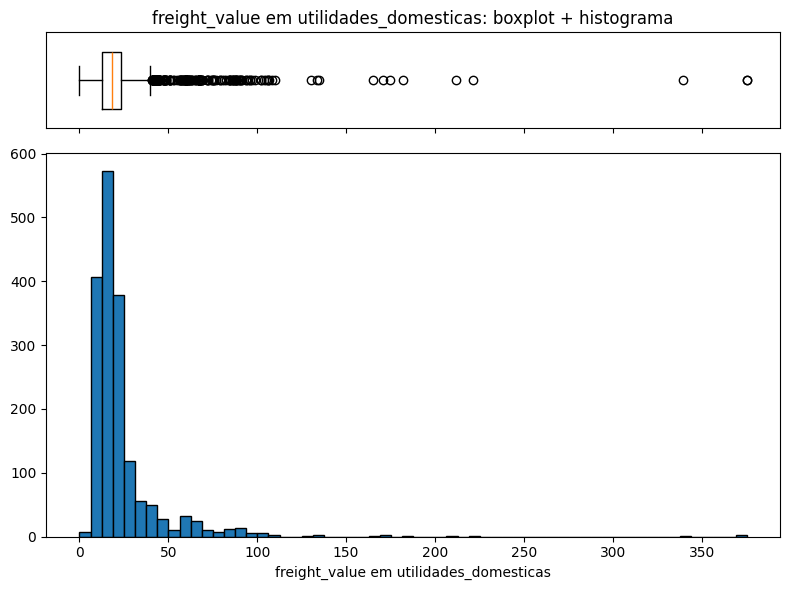

P(freight_value > 30) nesta categoria: 0.1586
P(freight_value > 30) na base inteira, do exercício 6: 0.1157

Frete médio e peso médio por grupo de mesmo_estado:
              freight_value  product_weight_g
mesmo_estado                                 
0                     30.30           2852.45
1                     14.99           2842.20

Correlação entre as variáveis do modelo:
                  freight_value  product_weight_g  volume_cm3   price  \
freight_value            1.0000            0.6919      0.6987  0.6666   
product_weight_g         0.6919            1.0000      0.8427  0.5948   
volume_cm3               0.6987            0.8427      1.0000  0.6101   
price                    0.6666            0.5948      0.6101  1.0000   
mesmo_estado            -0.3111           -0.0012      0.0111 -0.0755   

                  mesmo_estado  
freight_value          -0.3111  
product_weight_g       -0.0012  
volume_cm3              0.0111  
price                  -0.0755  
mesmo_est

In [ ]:
plotar_hist_box(df_utilidades["freight_value"], "freight_value em utilidades_domesticas")

frete_ordenado_utilidades = np.sort(df_utilidades["freight_value"])
p_frete_acima_30 = 1 - np.searchsorted(frete_ordenado_utilidades, 30, side = "right") / len(frete_ordenado_utilidades)

print("P(freight_value > 30) nesta categoria:", round(p_frete_acima_30, 4))
print("P(freight_value > 30) na base inteira, do exercício 6:", round(p_acima_30, 4))
print()

print("Frete médio e peso médio por grupo de mesmo_estado:")
print(df_utilidades.groupby("mesmo_estado")[["freight_value", "product_weight_g"]].mean().round(2))
print()

print("Correlação entre as variáveis do modelo:")
print(df_utilidades[colunas_modelo_multiplo].corr().round(4))

A distribuição do frete na categoria *utilidades_domesticas* tem a mesma cauda longa do resto da base, porém deslocada para cima. A média do frete é de R\$ 23,57, já a probabilidade de um item passar de R\$ 30,00 é de 15,86%, contra 11,57% da base completa, usando a mesma CDF empírica do exercício 6. Isso é coerente com o peso e volume mais alto encontrado na categoria, com peso médio de 2848g e volume médio de 20408cm³ nesse recorte.

Na matriz de correlação, o volume se correlaciona em 0,6987, peso com 0,6919 e preço com 0,6666, todas mais fortes do que na base inteira. A variável *mesmo_estado* aparece com -0,3111, com frete médio de R\$ 30,30 entre estados diferentes e 14,99 dentro do mesmo estado, mesmo com pouca variação do peso, 2852g contra 2842g.

### 14.3 Use IA generativa para acelerar ao menos uma etapa de limpeza ou análise, com revisão crítica documentada.

#### **Prompt enviado à LLM:**

Tenho um dataframe pandas chamado df_utilidades, com 1753 linhas, uma por item de pedido da categoria "utilidades_domesticas" de um marketplace, referente aos últimos três meses da base. Quero prever o valor do frete a partir das características do produto e da distância aproximada da entrega.

As colunas relevantes são:

- freight_value -> float, valor do frete do item, é a variável que quero prever
- product_weight_g -> float, peso do produto em gramas
- volume_cm3 -> float, volume do produto em cm³, calculado a partir do comprimento, altura e largura
- price -> float, preço do item
- mesmo_estado -> inteiro 0 ou 1, indica se o vendedor e o cliente estão no mesmo estado

Gere o código pandas e sklearn comentado que realize o diagnóstico de multicolinearidade entre as quatro preditoras usando o VIF (fator de inflação da variância), e explique como interpretar os valores encontrados, além de quais são as opções de tratamento caso o VIF fique alto. Não decida qual opção adotar, apenas apresente as opções com os prós e os contras de cada uma.

#### **Resposta da LLM:**

Embora a biblioteca `statsmodels` seja o padrão de mercado para calcular o VIF, é perfeitamente possível (e excelente para fins didáticos) implementar o cálculo utilizando o `LinearRegression` do `scikit-learn`. O VIF nada mais é do que a fórmula $1 / (1 - R^2)$, onde o $R^2$ é obtido ao tentar prever uma variável independente usando todas as outras.
Aqui está o código para diagnosticar o seu dataframe:

*[código gerado - colado na célula abaixo]*

Como interpretar os resultados do VIF
O VIF mede o quanto a variância (ou incerteza) de um coeficiente de regressão é inflada devido à correlação com as outras variáveis.

* VIF = 1: Não há correlação com as demais variáveis.
* VIF entre 1 e 5: Correlação moderada. Geralmente não exige intervenção.
* VIF > 5 (ou > 10, dependendo da literatura): Alta multicolinearidade. Como você já sabe que o peso e o volume têm $r = 0,84$, é esperado que o VIF de ambas supere a marca de 3,3 (já que $1 / (1 - 0.84^2) \approx 3.39$), podendo ser maior caso `price` também esteja correlacionado a elas.

Opções de tratamento para VIF alto
Se a correlação estiver prejudicando o modelo, você tem os seguintes caminhos:

* Opção 1: Remover uma das variáveis (ex: remover volume e manter peso)
   * Prós: Deixa o modelo mais simples, leve e fácil de interpretar.
   * Contras: Perde-se a informação residual útil. Um produto de 1kg que é minúsculo (um peso de academia) custa menos de frete do que um de 1kg que é gigante (uma almofada grande de algodão).
* Opção 2: Criar uma nova variável (Feature Engineering)
   * Prós: Mantém a informação de ambas. Você pode criar a coluna `densidade = product_weight_g / volume_cm3`.
   * Contras: A nova variável pode ter uma relação não-linear com o frete, exigindo transformações adicionais.
* Opção 3: Usar Regularização (Regressão Ridge ou Lasso)
   * Prós: O modelo lida matematicamente com a colinearidade sem precisar remover colunas. O Ridge encolhe os coeficientes, enquanto o Lasso pode zerar os menos importantes automaticamente.
   * Contras: Os coeficientes gerados perdem a interpretabilidade direta de negócio ("se subir 1kg, o frete sobe X reais"), pois são penalizados pelo algoritmo.
* Opção 4: Não fazer nada
   * Prós: Zero esforço de engenharia de dados.
   * Contras: Os coeficientes do modelo ficam altamente instáveis. No entanto, se o seu único objetivo for prever o frete com alta acurácia (e não interpretar o peso de cada variável na composição do preço), a multicolinearidade não afeta o poder preditivo geral do modelo.

#### **Código Gerado pela LLM:**

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Assumindo que o dataframe df_utilidades já está carregado na memória
preditoras = ['product_weight_g', 'volume_cm3', 'price', 'mesmo_estado']

# Inicializa o dataframe para armazenar os resultados
vif_data = pd.DataFrame()
vif_data["Variavel"] = preditoras
vif_valores = []

# Loop para calcular o R² e o VIF de cada variável
for var in preditoras:
    # Separa a variável atual como 'alvo' (y) e as demais como 'preditoras' (X)
    X = df_utilidades[preditoras].drop(columns=[var])
    y = df_utilidades[var]

    # Ajusta o modelo de regressão linear
    modelo = LinearRegression()
    modelo.fit(X, y)

    # Extrai o R²
    r_squared = modelo.score(X, y)

    # Calcula o VIF (com trava de segurança para divisão por zero)
    vif = 1 / (1 - r_squared) if r_squared < 1 else float('inf')
    vif_valores.append(vif)

vif_data["VIF"] = vif_valores

# Exibe os resultados ordenados do maior para o menor VIF
print(vif_data.sort_values(by="VIF", ascending=False))

           Variavel       VIF
1        volume_cm3  3.690714
0  product_weight_g  3.577165
2             price  1.669507
3      mesmo_estado  1.011013


#### **Revisão crítica:**

O código da LLM está correto e rodou sem nenhum ajuste, realizando o cálculo do VIF pela definição, fazendo a regressão de cada preditora contra as outras três, e aplicando a divisão de 1 por 1 menos o R² da regressão auxiliar.

Mesmo assim, ainda há algumas ressalvas, como a estimativa feita antes de rodar, em que a LLM diz que o VIF de peso e volume deve superar 3,39 pela conta 1 dividido por 1 menos 0,84 ao quadrado. Essa conta só é válida quando existe uma única preditora, e com quatro variáveis o R² auxiliar é calculado contra todas as outras ao mesmo tempo, então o VIF real ficou acima, 3,58 e 3,69, o que funcionou como uma aproximação, porém com uma justificativa errada. Outra ressalva é que não foi citada a comparação de desempenho do modelo com e sem a variável suspeita, que seria uma validação simples e ideal para ser feita inicialmente.

### 14.4 Construa e avalie um modelo de regressão múltipla prevendo freight_value a partir de ao menos três variáveis preditoras, incluindo peso e volume do produto.

In [ ]:
preditoras_frete = ["product_weight_g", "volume_cm3", "price", "mesmo_estado"]

X_multiplo = df_utilidades[preditoras_frete]
y_multiplo = df_utilidades["freight_value"]

X_treino_m, X_teste_m, y_treino_m, y_teste_m = train_test_split(X_multiplo, y_multiplo, test_size = 0.2, random_state = 42)

modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_treino_m, y_treino_m)

y_previsto_m = modelo_multiplo.predict(X_teste_m)

print("Itens em treino:", len(X_treino_m), "| itens em teste:", len(X_teste_m))
print("\nCoeficientes:")
print(pd.Series(modelo_multiplo.coef_, index = preditoras_frete).round(6))
print("\nCoeficiente linear:", round(modelo_multiplo.intercept_, 4))
print("R² no teste:", round(r2_score(y_teste_m, y_previsto_m), 4))
print("RMSE no teste:", round(np.sqrt(mean_squared_error(y_teste_m, y_previsto_m)), 4))
print("Frete médio no teste:", round(y_teste_m.mean(), 4))
print("Desvio padrão do frete no teste:", round(y_teste_m.std(), 4))

Itens em treino: 1402 | itens em teste: 351

Coeficientes:
product_weight_g     0.001591
volume_cm3           0.000279
price                0.050686
mesmo_estado       -14.330870
dtype: float64

Coeficiente linear: 14.7654
R² no teste: 0.5518
RMSE no teste: 12.6537
Frete médio no teste: 22.1692
Desvio padrão do frete no teste: 18.9288


Montei a regressão com as quatro preditoras, usando a mesma estratégia de validação do exercício 13 para os dois modelos serem comparáveis. O modelo ficou com R² de 0,5518 e RMSE de 12,6537 no teste, contra um frete médio de 22,17 reais e desvio padrão de 18,93.

Em unidade de negócio, cada grama a mais custa R\$ 0,001591, e cada cm³ custa R\$ 0,000279, cerca de 0,28 real por litro. Já cada real a mais no preço acrescenta só R\$ 0,05 de frete, o que confirma que o valor do produto quase não explica o frete, mesmo aparecendo com correlação de 0,6666 quando olhado sozinho.

Já o coeficiente *mesmo_estado* foi de -14,33, o que é de longe o maior efeito do modelo. Esse coeficiente indica que, mantendo peso, volume e preço constantes, uma entrega dentro do estado do vendedor custa em média R\$ 14,33 a menos. Isso mostra que o fator que estava ausente na explicação da dispersão em formato de leque dos scatter plots tem como principal explicação a distância da entrega, e não uma falha na medição de peso ou volume.

### 14.5 Diagnostique a multicolinearidade entre as preditoras e decida, com justificativa técnica, como tratá-la.

In [ ]:
modelos_comparados = {
    "peso + volume + preco + mesmo_estado": ["product_weight_g", "volume_cm3", "price", "mesmo_estado"],
    "sem volume": ["product_weight_g", "price", "mesmo_estado"],
    "sem peso": ["volume_cm3", "price", "mesmo_estado"],
    "so peso, como no exercicio 13": ["product_weight_g"],
}

linhas_comparacao = []

for nome_modelo, preditoras_testadas in modelos_comparados.items():
    r2_modelo, rmse_modelo = avaliar_modelo(df_utilidades, preditoras_testadas)
    linhas_comparacao.append({
        "modelo": nome_modelo,
        "n_preditoras": len(preditoras_testadas),
        "r2": round(r2_modelo, 4),
        "rmse": round(rmse_modelo, 4),
    })

comparacao_modelos = pd.DataFrame(linhas_comparacao)
print(comparacao_modelos)

                                 modelo  n_preditoras      r2     rmse
0  peso + volume + preco + mesmo_estado             4  0.5518  12.6537
1                            sem volume             3  0.5206  13.0876
2                              sem peso             3  0.5318  12.9340
3         so peso, como no exercicio 13             1  0.2808  16.0297


O VIF do item 14.3 deu 3,58 no peso e 3,69 no volume, com o preço em 1,67 e *mesmo_estado* em 1,01.

Também comparei o modelo completo com duas versões reduzidas, tirando o volume, o R² cai de 0,5518 para 0,5206 e o RMSE sobe de 12,65 para 13,09, e tirando o peso, o R² cai para 0,5318 e o RMSE sobe para 12,93. Ou seja, apesar de estarem correlacionadas, as duas carregam informação que a outra não cobre, por exemplo, um produto de 1kg pequeno e denso não custa o mesmo frete que um de 1kg grande e leve.

Decidi por manter as quatro preditoras, pelo VIF moderado somado a essa perda medida, já que o objetivo do modelo é prever para simular cenários de contrato, e não interpretar o quanto cada grama ou cada cm³ contribui isoladamente. A multicolinearidade deixa os coeficientes de peso e volume instáveis, mas não afeta a previsão conjunta nem o R².

### 14.6 Feche com um relato de cerca de uma página resumindo achados e limitações do modelo.

Este AT percorreu todo o caminho de um export bruto de marketplace até um modelo preditivo de frete avaliado. A partir de cinco arquivos CSV separados por domínio, que sozinhos não contavam a história inteira, fiz a consolidação em um único dataframe de 112650 linhas na granularidade de item de pedido, fazendo primeiro a correção do tipo das colunas de data, que o pandas havia lido como texto. Em cima dessa base, rodei a análise exploratória, as probabilidades, as correlações e, por fim, os modelos.

Referente aos achados, o mais consistente foi de que o valor do produto quase não explica o frete cobrado. Isso apareceu pela primeira vez no exercício 4, na reta ajustada manualmente entre preço médio e frete médio das categorias, em que o coeficiente angular de 0,0351 significava que 100 reais a mais no preço médio da categoria puxavam apenas 3,51 reais de frete, enquanto o coeficiente linear de 16,50 indicava um custo de base alto e independente do preço, depois no exercício 6, quando a previsão da reta para uma categoria 20% acima da média geral errou por 3,71 reais e, principalmente, quando ficou claro que categorias com preço médio praticamente igual tinham frete médio variando de 15,48 a 43,57 reais. Por fim, esse achado se confirmou no exercício 8, com o heatmap mostrando peso em 0,61 e volume em 0,59 contra apenas 0,41 do preço.

Outro achado é que a distância da entrega, que não foi possível medir com base nas informações trazidas nos arquivos csv, era o fator que faltava no frete. Os scatter plots do exercício 8 mostravam uma associação positiva em formato de leque, com itens de peso semelhante pagando fretes muito diferentes, no exercício 14, ao criar a variável mesmo_estado como aproximação, o efeito apareceu com força, entregas dentro do estado do vendedor custam em média 14,33 reais a menos de frete mantidas as características do produto, e o frete médio observado cai de 30,30 para 14,99 reais entre os dois grupos, com peso médio praticamente idêntico, sendo a variável de maior efeito do modelo final.

O terceiro achado foi o efeito do atraso na satisfação. O atraso na entrega é a variável mais associada à nota do cliente, com correlação de -0,365 no exercício 9, muito à frente de frete e peso. O atraso é raro, acontece em 8,11% dos pedidos entregues, mas quando acontece o impacto é severo, e o exercício 11 dimensionou isso dentro de uma categoria, a proporção de avaliações negativas sobe de 14,77% nas entregas adiantadas para 78,64% nos atrasos maiores que uma semana.

Sobre o modelo, a regressão múltipla final prevê o frete da categoria *utilidades_domesticas* nos últimos três meses da base a partir de peso, volume, preço e mesmo_estado, e alcançou R² de 0,5518 e RMSE de 12,65 reais no conjunto de teste. É um grande salto em relação à regressão simples realizada no exercício 13, que ficou em R² de 0,3775 usando só o peso, e maior ainda em relação ao mesmo recorte com apenas o peso, que daria 0,2808. Fiz o diagnóstico da multicolinearidade entre peso e volume com o VIF, que ficou em 3,58 e 3,69, na faixa moderada, e decidi manter as duas variáveis porque a remoção de qualquer uma piora a previsão e porque o objetivo do modelo é prever, não interpretar coeficientes isolados.

Sobre as limitações, a primeira é que o modelo ainda explica pouco mais da metade da variação do frete, e o erro típico de 12,65 reais é alto contra um frete médio de 22,17. Ele serve para simular cenários agregados de contrato, não para precificar item a item. Outra limitação é que a mesmo_estado é uma aproximação grosseira de distância, que trata com o mesmo peso uma entrega na mesma cidade e outra entre pontas opostas de um estado, e o ganho que ela trouxe sugere que uma medida real de distância melhoraria bastante o ajuste. Além disso, a heterocedasticidade, já visível nos scatter plots do exercício 8, é uma limitação, já que o erro do modelo cresce junto com o peso e o volume, então ele acerta mais nos itens leves e erra mais justamente nos pesados, que são os que mais pesam no custo. Por fim, o modelo foi ajustado sobre uma única categoria e uma janela de três meses, com 1753 itens, então os coeficientes não devem ser extrapolados para outras categorias nem para períodos diferentes sem realizar nenhum ajuste.

Por fim, sobre o uso de IA generativa, ela acelerou algumas etapas do trabalho, como a limpeza do recorte do exercício 10, a formulação das perguntas analíticas e o código descritivo do exercício 11, e o diagnóstico de multicolinearidade do exercício 14. Em todos os casos, a revisão crítica encontrou algo a corrigir, desde a exclusão de 1553 linhas legítimas por uma chave de deduplicação incompleta, até uma justificativa estatística errada para estimar o VIF e uma proposta de análise que ignorava o tamanho do efeito em favor do p-valor, mostrando que o uso de IA generativa traz um ganho em performance, porém deve ser sempre acompanhada de uma análise e revisão crítica para garantir que tudo está correto.



## Modelo de LLM utilizado

Todos os prompts registrados nos exercícios que pedem a utilização de uma LLM foram enviados ao **Gemini Pro 3.1**, do Google, acessado pela interface de chat.

Além disso, o Gemini também foi utilizado como uma ferramenta auxiliar na consulta de sintaxe de comandos, funções e parâmetros.